# Pemodelan Regresi Tingkat Resistensi Antimikroba Berbasis Penggunaan Antibiotik dan Faktor Epidemiologis untuk Mendukung Surveilans Kesehatan Masyarakat

## 1. Pengetahuan Umum Proyek

| Aspek | Keterangan |
|---|---|
| **Judul** | Pemodelan Regresi Tingkat Resistensi Antimikroba Berbasis Penggunaan Antibiotik dan Faktor Epidemiologis untuk Mendukung Surveilans Kesehatan Masyarakat |
| **Bidang** | Data Science, Machine Learning (Supervised Learning – Regresi), Kesehatan Masyarakat |
| **Latar belakang** | *Antimicrobial Resistance* (AMR) terjadi ketika mikroba tidak lagi mempan terhadap obat yang sebelumnya efektif. Penggunaan antibiotik yang tidak tepat mempercepat proses ini sehingga infeksi makin sulit diobati, biaya perawatan naik, dan risiko kematian meningkat. Surveilans yang baik membutuhkan alat bantu untuk memantau dan memperkirakan tingkat resistensi. |
| **Tujuan** | (1) Memahami pola resistensi antar negara dan antar tahun, (2) menguji keterkaitan penggunaan antibiotik & faktor epidemiologis dengan resistensi, (3) membangun model regresi untuk memprediksi `resistance_rate`, (4) menemukan negara yang resistensinya jauh melebihi prediksi sebagai kandidat prioritas surveilans. |
| **Unit analisis** | Satu baris = satu kombinasi **negara–tahun** |
| **Variabel target** | `resistance_rate` (tingkat resistensi, %) |
| **Sumber data (3 tabel)** | `amr_resistance.csv` (resistensi), `antibiotic_use.csv` (konsumsi & komposisi antibiotik), `epidemiological_factors.csv` (populasi, insidensi, mortalitas infeksi) |
| **Fitur utama** | `antibiotic_use_ddd`, `access_percent`, `watch_percent`, `reserve_percent` (klasifikasi AWaRe WHO), `log_population`, `infection_incidence`, `mortality_rate` (hasil rekayasa fitur), `year` |
| **Algoritma** | Baseline rata-rata (*Dummy*), **Ridge Regression**, **Random Forest Regressor**, **Gradient Boosting Regressor**; model terbaik di-*tuning* dengan `GridSearchCV` |
| **Validasi** | KFold acak vs **GroupKFold per negara** (menguji kemampuan model pada negara yang belum pernah dilihat), hold-out per negara |
| **Metrik** | R², MAE, RMSE |
| **Interpretasi model** | *Permutation importance*, *Partial Dependence Plot*, analisis residual per negara |

**Catatan istilah AWaRe (WHO):** *Access* = antibiotik lini pertama berisiko resistensi rendah; *Watch* = berpotensi memicu resistensi sehingga perlu dipantau; *Reserve* = cadangan terakhir untuk infeksi yang kebal obat lain.

**Alur kerja:** Pertanyaan → Import library → Data gathering → Assessing (per tabel) → Cleaning → Assessing ulang → Penggabungan & rekayasa fitur → EDA berbasis pertanyaan → Pemodelan regresi → Simpulan.

## 2. Pertanyaan Analisis

Seluruh pertanyaan di bawah ini dijawab pada bagian **Simpulan** di akhir notebook, dengan angka yang dihitung langsung dari data.

| No | Jenis | Pertanyaan |
|---|---|---|
| **Q1** | Basic | Bagaimana distribusi `resistance_rate` dan bagaimana tren rata-ratanya dari tahun ke tahun? Negara mana yang resistensinya paling tinggi dan paling meningkat? |
| **Q2** | Analisis | Apakah negara/tahun dengan penggunaan antibiotik lebih tinggi dan porsi antibiotik *Watch/Reserve* lebih besar memiliki resistensi lebih tinggi? Apakah hubungan itu sama ketika membandingkan **antar negara** dengan melihat **perubahan di dalam satu negara** dari waktu ke waktu? |
| **Q3** | Analisis | Bagaimana beban epidemiologis (insidensi dan mortalitas infeksi) berkaitan dengan resistensi, dan negara mana yang resistensinya **jauh lebih tinggi dari yang diprediksi** dari faktor-faktornya (kandidat prioritas surveilans)? |
| **Q4** | AI | Seberapa akurat model regresi (Ridge, Random Forest, Gradient Boosting) memprediksi resistensi **pada negara yang belum pernah dilihat model**, dan fitur apa yang paling berpengaruh terhadap prediksi? |

## 3. Import Library

In [ ]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import (GridSearchCV, GroupKFold, GroupShuffleSplit,
                                     KFold, cross_val_predict, cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

RANDOM_STATE = 42
TARGET = "resistance_rate"
KEYS = ["country", "year"]
print("Library siap digunakan.")

Library siap digunakan.


## 4. Data Wrangling

### 4.1 Data Gathering
Membaca tiga tabel sumber. Jika file belum ada di Colab, sel ini otomatis meminta unggahan.

In [ ]:
FILE_MAP = {
    "amr": "amr_resistance.csv",
    "antibiotic": "antibiotic_use.csv",
    "epi": "epidemiological_factors.csv",
}

if not all(os.path.exists(f) for f in FILE_MAP.values()):
    try:
        from google.colab import files
        print("Unggah ketiga file CSV:", list(FILE_MAP.values()))
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Letakkan file berikut di folder kerja: {list(FILE_MAP.values())}")

amr_raw = pd.read_csv(FILE_MAP["amr"])
antibiotic_raw = pd.read_csv(FILE_MAP["antibiotic"])
epi_raw = pd.read_csv(FILE_MAP["epi"])

REQUIRED = {
    "amr": ["country", "year", "resistance_rate"],
    "antibiotic": ["country", "year", "antibiotic_use_ddd", "access_percent", "watch_percent", "reserve_percent"],
    "epi": ["country", "year", "population", "infection_incidence", "infection_mortality"],
}
raw_tables = {"amr": amr_raw, "antibiotic": antibiotic_raw, "epi": epi_raw}

ringkasan = []
for key, d in raw_tables.items():
    kolom_hilang = [c for c in REQUIRED[key] if c not in d.columns]
    ringkasan.append({"tabel": FILE_MAP[key], "baris": d.shape[0], "kolom": d.shape[1],
                      "daftar_kolom": ", ".join(d.columns), "kolom_wajib_hilang": kolom_hilang or "-"})
display(pd.DataFrame(ringkasan))

for key, d in raw_tables.items():
    print(f"\n=== {FILE_MAP[key]} (5 baris pertama) ===")
    display(d.head())

,tabel,baris,kolom,daftar_kolom,kolom_wajib_hilang
0,amr_resistance.csv,1497,5,"country, year, resistance_rate, pathogen, anti...",-
1,antibiotic_use.csv,416,6,"country, year, antibiotic_use_ddd, access_perc...",-
2,epidemiological_factors.csv,4402,5,"country, year, population, infection_incidence...",-



=== amr_resistance.csv (5 baris pertama) ===


,country,year,resistance_rate,pathogen,antibiotic
0,NPL,2021,57.890,Staphylococcus aureus,Methicillin
1,BRN,2020,12.470,Staphylococcus aureus,Methicillin
2,MMR,2018,74.100,Staphylococcus aureus,Methicillin
3,NGA,2021,66.670,Staphylococcus aureus,Methicillin
4,ZAF,2022,16.480,Staphylococcus aureus,Methicillin



=== antibiotic_use.csv (5 baris pertama) ===


,country,year,antibiotic_use_ddd,access_percent,watch_percent,reserve_percent
0,ROU,2017,25.370,54.731,45.099,0.085
1,ROU,2023,28.723,51.493,48.224,0.215
2,MLI,2019,11.355,55.532,44.362,0.003
3,MDV,2018,25.226,35.718,63.246,0.000
4,GEO,2020,14.417,52.632,45.501,0.220



=== epidemiological_factors.csv (5 baris pertama) ===


,country,year,population,infection_incidence,infection_mortality
0,AFG,2000,20130327,148.000,10000
1,AFG,2001,20284307,175.000,11000
2,AFG,2002,21378117,197.000,13000
3,AFG,2003,22733049,215.000,15000
4,AFG,2004,23560654,228.000,16000


### 4.2 Assessing Data
Fungsi di bawah menilai satu tabel secara menyeluruh: ukuran, contoh data, tipe data (`info`), statistik deskriptif, nilai kosong, duplikasi, konsistensi teks, validitas nilai (negatif, `inf`, persentase di luar 0–100), cakupan negara–tahun, dan outlier (aturan IQR).

In [ ]:
SPEC = {
    "amr": dict(numeric=["year", "resistance_rate"], percent=["resistance_rate"], nonneg=["resistance_rate"]),
    "antibiotic": dict(numeric=["year", "antibiotic_use_ddd", "access_percent", "watch_percent", "reserve_percent"],
                       percent=["access_percent", "watch_percent", "reserve_percent"],
                       nonneg=["antibiotic_use_ddd", "access_percent", "watch_percent", "reserve_percent"]),
    "epi": dict(numeric=["year", "population", "infection_incidence", "infection_mortality"],
                percent=[], nonneg=["population", "infection_incidence", "infection_mortality"]),
}


def _to_num(frame, cols):
    cols = [c for c in cols if c in frame.columns]
    return frame[cols].apply(pd.to_numeric, errors="coerce") if cols else pd.DataFrame(index=frame.index)


def quality_summary(df, name, spec):
    keys = [k for k in KEYS if k in df.columns]
    num = df.select_dtypes(include=np.number)
    pct, nn = _to_num(df, spec["percent"]), _to_num(df, spec["nonneg"])
    return {
        "tabel": name, "baris": len(df), "kolom": df.shape[1],
        "nilai_kosong": int(df.isnull().sum().sum()),
        "duplikat_penuh": int(df.duplicated().sum()),
        "duplikat_kunci(country,year)": int(df.duplicated(subset=keys).sum()) if keys else np.nan,
        "nilai_inf": int(np.isinf(num).sum().sum()),
        "nilai_negatif": int((nn < 0).sum().sum()),
        "persen_di_luar_0_100": int(((pct < 0) | (pct > 100)).sum().sum()),
    }


def assess_table(df, name, spec):
    line = "=" * 95
    print(line); print(f"ASSESSING TABEL: {name}"); print(line)

    print(f"\n[1] Ukuran data : {df.shape[0]:,} baris x {df.shape[1]} kolom")
    print("\n[2] Contoh data"); display(df.head())
    print("\n[3] Info tipe data"); df.info()

    num = df.select_dtypes(include=np.number)
    cat = df.select_dtypes(exclude=np.number)
    print("\n[4] Statistik deskriptif kolom numerik (describe + skewness)")
    if not num.empty:
        desc = num.describe().T
        desc["skew"] = num.skew()
        display(desc)
    print("\n[5] Statistik deskriptif kolom kategorikal")
    if not cat.empty:
        display(cat.describe().T)
    else:
        print("   (tidak ada kolom kategorikal)")

    print("\n[6] Nilai kosong (missing value)")
    miss = pd.DataFrame({"jumlah_kosong": df.isnull().sum(), "persen_kosong": df.isnull().mean() * 100})
    display(miss)
    print(f"   Total sel kosong: {int(df.isnull().sum().sum()):,} | baris dengan >=1 nilai kosong: {int(df.isnull().any(axis=1).sum()):,}")

    keys = [k for k in KEYS if k in df.columns]
    print("\n[7] Duplikasi")
    print(f"   Duplikat identik satu baris penuh : {int(df.duplicated().sum()):,}")
    if keys:
        print(f"   Baris dengan kunci {keys} berulang  : {int(df.duplicated(subset=keys).sum()):,}")

    print("\n[8] Konsistensi teks (spasi liar / variasi huruf)")
    teks = [c for c in cat.columns]
    if teks:
        rows = []
        for c in teks:
            s = df[c].dropna().astype(str)
            norm = s.str.strip().str.replace(r"\s+", " ", regex=True).str.casefold()
            rows.append({"kolom": c, "nilai_unik_asli": s.nunique(), "nilai_unik_setelah_normalisasi": norm.nunique(),
                         "baris_dengan_spasi_liar": int((s != s.str.strip()).sum())})
        display(pd.DataFrame(rows))

    print("\n[9] Validitas nilai")
    salah_tipe = []
    for c in spec["numeric"]:
        if c in df.columns and df[c].dtype == object:
            bad = int(pd.to_numeric(df[c], errors="coerce").isna().sum() - df[c].isna().sum())
            salah_tipe.append({"kolom": c, "dtype": str(df[c].dtype), "nilai_tidak_bisa_diubah_ke_angka": bad})
    if salah_tipe:
        print("   Kolom numerik yang terbaca sebagai teks:"); display(pd.DataFrame(salah_tipe))
    q = quality_summary(df, name, spec)
    print(f"   Nilai inf: {q['nilai_inf']} | nilai negatif tidak valid: {q['nilai_negatif']} | persentase di luar 0-100: {q['persen_di_luar_0_100']}")

    print("\n[10] Cakupan negara dan tahun")
    if "country" in df.columns:
        print(f"   Jumlah negara unik: {df['country'].nunique()}")
    if "year" in df.columns:
        yr = pd.to_numeric(df["year"], errors="coerce")
        print(f"   Rentang tahun     : {yr.min():.0f} - {yr.max():.0f} ({yr.nunique()} tahun unik)")

    print("\n[11] Outlier (aturan IQR: di luar Q1-1.5*IQR dan Q3+1.5*IQR)")
    rows = []
    for c in num.columns:
        if c == "year":
            continue
        q1, q3 = num[c].quantile([0.25, 0.75]); iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_out = int(((num[c] < lo) | (num[c] > hi)).sum())
        rows.append({"kolom": c, "batas_bawah": lo, "batas_atas": hi, "jumlah_outlier": n_out,
                     "persen_outlier": n_out / max(num[c].notna().sum(), 1) * 100})
    if rows:
        display(pd.DataFrame(rows))
    print()
    return q

#### 4.2.1 Assessing tabel `amr_resistance`

In [ ]:
q_amr_before = assess_table(amr_raw, "amr_resistance (SEBELUM cleaning)", SPEC["amr"])

for c in [c for c in ["pathogen", "antibiotic"] if c in amr_raw.columns]:
    print(f"Kolom '{c}': {amr_raw[c].nunique()} nilai unik")
bocor = [c for c in ["predicted_resistance_rate", "prediction_error", "absolute_error"] if c in amr_raw.columns]
if bocor:
    print(f"\nPERINGATAN kebocoran data (data leakage): kolom {bocor} adalah HASIL prediksi, bukan data asli. "
          "Kolom ini tidak boleh dipakai sebagai fitur dan akan dibuang saat cleaning.")

ASSESSING TABEL: amr_resistance (SEBELUM cleaning)

[1] Ukuran data : 1,497 baris x 5 kolom

[2] Contoh data


,country,year,resistance_rate,pathogen,antibiotic
0,NPL,2021,57.890,Staphylococcus aureus,Methicillin
1,BRN,2020,12.470,Staphylococcus aureus,Methicillin
2,MMR,2018,74.100,Staphylococcus aureus,Methicillin
3,NGA,2021,66.670,Staphylococcus aureus,Methicillin
4,ZAF,2022,16.480,Staphylococcus aureus,Methicillin



[3] Info tipe data
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1497 entries, 0 to 1496
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   country          1497 non-null   object 
 1   year             1497 non-null   int64  
 2   resistance_rate  1497 non-null   float64
 3   pathogen         1497 non-null   object 
 4   antibiotic       1497 non-null   object 
dtypes: float64(1), int64(1), object(3)
memory usage: 58.6+ KB

[4] Statistik deskriptif kolom numerik (describe + skewness)


,count,mean,std,min,25%,50%,75%,max,skew
year,"1,497.000","2,020.357",2.039,"2,016.000","2,019.000","2,021.000","2,022.000","2,023.000",-0.371
resistance_rate,"1,497.000",32.601,24.860,0.000,11.100,29.410,48.800,100.000,0.673



[5] Statistik deskriptif kolom kategorikal


...

   Total sel kosong: 0 | baris dengan >=1 nilai kosong: 0

[7] Duplikasi
   Duplikat identik satu baris penuh : 998
   Baris dengan kunci ['country', 'year'] berulang  : 998

[8] Konsistensi teks (spasi liar / variasi huruf)


,kolom,nilai_unik_asli,nilai_unik_setelah_normalisasi,baris_dengan_spasi_liar
0,country,101,101,0
1,pathogen,1,1,0
2,antibiotic,1,1,0



[9] Validitas nilai
   Nilai inf: 0 | nilai negatif tidak valid: 0 | persentase di luar 0-100: 0

[10] Cakupan negara dan tahun
   Jumlah negara unik: 101
   Rentang tahun     : 2016 - 2023 (8 tahun unik)

[11] Outlier (aturan IQR: di luar Q1-1.5*IQR dan Q3+1.5*IQR)


,kolom,batas_bawah,batas_atas,jumlah_outlier,persen_outlier
0,resistance_rate,-45.450,105.350,0,0.000



Kolom 'pathogen': 1 nilai unik
Kolom 'antibiotic': 1 nilai unik


#### 4.2.2 Assessing tabel `antibiotic_use`

In [ ]:
q_abx_before = assess_table(antibiotic_raw, "antibiotic_use (SEBELUM cleaning)", SPEC["antibiotic"])

aware = _to_num(antibiotic_raw, ["access_percent", "watch_percent", "reserve_percent"]).sum(axis=1, min_count=3)
print("Pemeriksaan komposisi AWaRe: access + watch + reserve seharusnya mendekati 100")
display(aware.describe().to_frame("total_aware_percent").T)
print(f"Baris dengan total menyimpang >5 poin dari 100: {int(((aware - 100).abs() > 5).sum())}")

ASSESSING TABEL: antibiotic_use (SEBELUM cleaning)

[1] Ukuran data : 416 baris x 6 kolom

[2] Contoh data


,country,year,antibiotic_use_ddd,access_percent,watch_percent,reserve_percent
0,ROU,2017,25.370,54.731,45.099,0.085
1,ROU,2023,28.723,51.493,48.224,0.215
2,MLI,2019,11.355,55.532,44.362,0.003
3,MDV,2018,25.226,35.718,63.246,0.000
4,GEO,2020,14.417,52.632,45.501,0.220



[3] Info tipe data
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 416 entries, 0 to 415
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   country             416 non-null    object 
 1   year                416 non-null    int64  
 2   antibiotic_use_ddd  416 non-null    float64
 3   access_percent      416 non-null    float64
 4   watch_percent       416 non-null    float64
 5   reserve_percent     416 non-null    float64
dtypes: float64(4), int64(1), object(1)
memory usage: 19.6+ KB

[4] Statistik deskriptif kolom numerik (describe + skewness)


,count,mean,std,min,25%,50%,75%,max,skew
year,416.000,"2,019.938",2.241,"2,016.000","2,018.000","2,020.000","2,022.000","2,023.000",-0.243
antibiotic_use_ddd,416.000,19.988,11.107,3.270,12.756,18.411,24.118,118.929,3.139
access_percent,416.000,62.559,14.218,18.226,52.598,63.134,72.868,91.914,-0.438
watch_percent,416.000,36.230,13.579,5.332,26.102,36.007,45.193,78.055,0.398
reserve_percent,416.000,0.239,0.552,0.000,0.038,0.139,0.282,8.964,11.366



[5] Statistik deskriptif kolom kategorikal


...


[9] Validitas nilai
   Nilai inf: 0 | nilai negatif tidak valid: 0 | persentase di luar 0-100: 0

[10] Cakupan negara dan tahun
   Jumlah negara unik: 73
   Rentang tahun     : 2016 - 2023 (8 tahun unik)

[11] Outlier (aturan IQR: di luar Q1-1.5*IQR dan Q3+1.5*IQR)


,kolom,batas_bawah,batas_atas,jumlah_outlier,persen_outlier
0,antibiotic_use_ddd,-4.288,41.162,16,3.846
1,access_percent,22.194,103.272,2,0.481
2,watch_percent,-2.535,73.830,3,0.721
3,reserve_percent,-0.328,0.648,22,5.288



Pemeriksaan komposisi AWaRe: access + watch + reserve seharusnya mendekati 100


,count,mean,std,min,25%,50%,75%,max
total_aware_percent,416.000,99.028,2.599,78.426,99.274,99.977,100.000,100.000


Baris dengan total menyimpang >5 poin dari 100: 17


#### 4.2.3 Assessing tabel `epidemiological_factors`

In [ ]:
q_epi_before = assess_table(epi_raw, "epidemiological_factors (SEBELUM cleaning)", SPEC["epi"])

ASSESSING TABEL: epidemiological_factors (SEBELUM cleaning)

[1] Ukuran data : 4,402 baris x 5 kolom

[2] Contoh data


,country,year,population,infection_incidence,infection_mortality
0,AFG,2000,20130327,148.000,10000
1,AFG,2001,20284307,175.000,11000
2,AFG,2002,21378117,197.000,13000
3,AFG,2003,22733049,215.000,15000
4,AFG,2004,23560654,228.000,16000



[3] Info tipe data
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4402 entries, 0 to 4401
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   country              4402 non-null   object 
 1   year                 4402 non-null   int64  
 2   population           4402 non-null   int64  
 3   infection_incidence  4402 non-null   float64
 4   infection_mortality  4402 non-null   int64  
dtypes: float64(1), int64(3), object(1)
memory usage: 172.1+ KB

[4] Statistik deskriptif kolom numerik (describe + skewness)


,count,mean,std,min,25%,50%,75%,max,skew
year,"4,402.000","2,012.045",7.200,"2,000.000","2,006.000","2,012.000","2,018.000","2,024.000",-0.007
population,"4,402.000","40,387,339.728","143,949,678.898","37,548.000","3,027,953.750","9,304,959.000","28,406,971.750","1,450,935,791.000",8.036
infection_incidence,"4,402.000",161.427,227.717,0.290,21.000,73.000,211.000,"2,700.000",3.121
infection_mortality,"4,402.000","8,327.129","40,516.159",0.000,61.000,530.000,"2,975.000","848,000.000",12.050



[5] Statistik deskriptif kolom kategorikal


...

,jumlah_kosong,persen_kosong
country,0,0.000
year,0,0.000
population,0,0.000
infection_incidence,0,0.000
infection_mortality,0,0.000


   Total sel kosong: 0 | baris dengan >=1 nilai kosong: 0

[7] Duplikasi
   Duplikat identik satu baris penuh : 0
   Baris dengan kunci ['country', 'year'] berulang  : 0

[8] Konsistensi teks (spasi liar / variasi huruf)


,kolom,nilai_unik_asli,nilai_unik_setelah_normalisasi,baris_dengan_spasi_liar
0,country,177,177,0



[9] Validitas nilai
   Nilai inf: 0 | nilai negatif tidak valid: 0 | persentase di luar 0-100: 0

[10] Cakupan negara dan tahun
   Jumlah negara unik: 177
   Rentang tahun     : 2000 - 2024 (25 tahun unik)

[11] Outlier (aturan IQR: di luar Q1-1.5*IQR dan Q3+1.5*IQR)


,kolom,batas_bawah,batas_atas,jumlah_outlier,persen_outlier
0,population,"-35,040,573.250","66,475,498.750",499,11.336
1,infection_incidence,-264.000,496.000,339,7.701
2,infection_mortality,"-4,310.000","7,346.000",639,14.516


### 4.3 Cleaning Data
Keputusan cleaning, berdasarkan temuan assessing:

1. **Standarisasi nama kolom dan teks** (spasi liar, nama negara) agar penggabungan tabel tidak gagal.
2. **Buang kolom hasil prediksi** (`predicted_resistance_rate`, `prediction_error`, `absolute_error`) karena menyebabkan *data leakage*.
3. **Ubah ke tipe angka**, `inf` dijadikan kosong, dan nilai mustahil (negatif, persentase di luar 0–100) dijadikan kosong.
4. **Hapus duplikat identik**, lalu rata-ratakan baris yang kunci `country–year`-nya berulang agar satu negara–tahun hanya satu baris (mencegah baris ganda saat merge).
5. **Imputasi** nilai kosong fitur: interpolasi linear per negara menurut tahun, lalu median per negara, lalu median global. **Target (`resistance_rate`) tidak diimputasi**; barisnya dibuang.
6. **Outlier dipertahankan** karena nilai ekstrem populasi/insidensi bersifat nyata (bukan salah input). Penanganannya lewat transformasi log dan model berbasis pohon.

In [ ]:
LEAK_COLS = ["predicted_resistance_rate", "prediction_error", "absolute_error"]
cleaning_log = []


def log_step(tabel, langkah, jumlah):
    cleaning_log.append({"tabel": tabel, "langkah": langkah, "jumlah_terdampak": int(jumlah)})


def standardize(df, name):
    d = df.copy()
    d.columns = d.columns.str.strip().str.lower().str.replace(r"\s+", "_", regex=True)
    for c in d.select_dtypes(include=["object", "string"]).columns:
        d[c] = (d[c].astype("string").str.strip().str.replace(r"\s+", " ", regex=True).replace("", pd.NA))
    d["year"] = pd.to_numeric(d["year"], errors="coerce")
    n0 = len(d)
    d = d.dropna(subset=KEYS).copy()
    d["year"] = d["year"].astype(int)
    d["country"] = d["country"].astype(str)
    log_step(name, "baris dibuang karena country/year kosong", n0 - len(d))
    return d


def sanitize_numeric(d, name, spec):
    d = d.copy()
    cols = [c for c in spec["numeric"] if c in d.columns and c != "year"]
    for c in cols:
        before_na = d[c].isna().sum()
        d[c] = pd.to_numeric(d[c], errors="coerce")
        log_step(name, f"{c}: teks non-angka -> kosong", d[c].isna().sum() - before_na)
        n_inf = np.isinf(d[c]).sum()
        d[c] = d[c].replace([np.inf, -np.inf], np.nan)
        log_step(name, f"{c}: inf -> kosong", n_inf)
    for c in [c for c in spec["nonneg"] if c in d.columns]:
        neg = (d[c] < 0).sum()
        d.loc[d[c] < 0, c] = np.nan
        log_step(name, f"{c}: nilai negatif -> kosong", neg)
    for c in [c for c in spec["percent"] if c in d.columns]:
        out = (d[c] > 100).sum()
        d.loc[d[c] > 100, c] = np.nan
        log_step(name, f"{c}: nilai >100% -> kosong", out)
    return d


def impute_by_country(d, name, cols):
    d = d.sort_values(KEYS).reset_index(drop=True)
    for c in cols:
        n_na = d[c].isna().sum()
        if n_na == 0:
            continue
        d[c] = d.groupby("country")[c].transform(lambda s: s.interpolate(limit_direction="both"))
        d[c] = d[c].fillna(d.groupby("country")[c].transform("median"))
        d[c] = d[c].fillna(d[c].median())
        log_step(name, f"{c}: nilai kosong diimputasi", n_na)
    return d


def dedupe_and_aggregate(d, name, num_cols):
    n_full = d.duplicated().sum()
    d = d.drop_duplicates().copy()
    log_step(name, "duplikat identik dihapus", n_full)
    n_key = d.duplicated(subset=KEYS).sum()
    d = d.groupby(KEYS, as_index=False)[num_cols].mean()
    log_step(name, "baris kunci country-year berulang digabung (rata-rata)", n_key)
    return d


# ---------- Tabel 1: AMR ----------
amr_c = standardize(amr_raw, "amr")
amr_c = amr_c.drop(columns=[c for c in LEAK_COLS if c in amr_c.columns])
log_step("amr", "kolom hasil prediksi dibuang (leakage)", sum(c in amr_raw.columns for c in LEAK_COLS))
amr_c = sanitize_numeric(amr_c, "amr", SPEC["amr"])
n_full = amr_c.duplicated().sum()
amr_c = amr_c.drop_duplicates()
log_step("amr", "duplikat identik dihapus", n_full)
n_na = amr_c[TARGET].isna().sum()
amr_c = amr_c.dropna(subset=[TARGET])
log_step("amr", "baris dibuang karena target kosong", n_na)
grp = amr_c.groupby(KEYS)
amr_clean = grp.agg(resistance_rate=(TARGET, "mean"), n_records=(TARGET, "size")).reset_index()
if "pathogen" in amr_c.columns:
    amr_clean["n_pathogen"] = grp["pathogen"].nunique().values
if "antibiotic" in amr_c.columns:
    amr_clean["n_antibiotic_tested"] = grp["antibiotic"].nunique().values
log_step("amr", "baris diringkas ke satu baris per country-year", len(amr_c) - len(amr_clean))

# ---------- Tabel 2: Antibiotic use ----------
abx = standardize(antibiotic_raw, "antibiotic")
abx = sanitize_numeric(abx, "antibiotic", SPEC["antibiotic"])
abx_num = [c for c in SPEC["antibiotic"]["numeric"] if c != "year"]
abx = dedupe_and_aggregate(abx, "antibiotic", abx_num)
antibiotic_clean = impute_by_country(abx, "antibiotic", abx_num)

# ---------- Tabel 3: Epidemiological factors ----------
epi_c = standardize(epi_raw, "epi")
epi_c = sanitize_numeric(epi_c, "epi", SPEC["epi"])
epi_num = [c for c in SPEC["epi"]["numeric"] if c != "year"]
epi_c = dedupe_and_aggregate(epi_c, "epi", epi_num)
epi_clean = impute_by_country(epi_c, "epi", epi_num)

log_df = pd.DataFrame(cleaning_log)
print("Log cleaning (hanya langkah yang berdampak):")
display(log_df[log_df["jumlah_terdampak"] > 0].reset_index(drop=True))

Log cleaning (hanya langkah yang berdampak):


,tabel,langkah,jumlah_terdampak
0,amr,duplikat identik dihapus,998


### 4.4 Assessing Ulang (setelah cleaning)

In [ ]:
q_amr_after = assess_table(amr_clean, "amr_resistance (SESUDAH cleaning)", SPEC["amr"])

ASSESSING TABEL: amr_resistance (SESUDAH cleaning)

[1] Ukuran data : 499 baris x 6 kolom

[2] Contoh data


,country,year,resistance_rate,n_records,n_pathogen,n_antibiotic_tested
0,ARE,2017,34.100,1,1,1
1,ARE,2018,23.700,1,1,1
2,ARE,2019,36.230,1,1,1
3,ARE,2020,42.520,1,1,1
4,ARE,2021,35.650,1,1,1



[3] Info tipe data
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 499 entries, 0 to 498
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   country              499 non-null    object 
 1   year                 499 non-null    int64  
 2   resistance_rate      499 non-null    float64
 3   n_records            499 non-null    int64  
 4   n_pathogen           499 non-null    int64  
 5   n_antibiotic_tested  499 non-null    int64  
dtypes: float64(1), int64(4), object(1)
memory usage: 23.5+ KB

[4] Statistik deskriptif kolom numerik (describe + skewness)


,count,mean,std,min,25%,50%,75%,max,skew
year,499.000,"2,020.357",2.040,"2,016.000","2,019.000","2,021.000","2,022.000","2,023.000",-0.372
resistance_rate,499.000,32.601,24.877,0.000,11.125,29.410,48.715,100.000,0.675
n_records,499.000,1.000,0.000,1.000,1.000,1.000,1.000,1.000,0.000
n_pathogen,499.000,1.000,0.000,1.000,1.000,1.000,1.000,1.000,0.000
n_antibiotic_tested,499.000,1.000,0.000,1.000,1.000,1.000,1.000,1.000,0.000



[5] Statistik deskriptif kolom kategorikal


...

,jumlah_kosong,persen_kosong
country,0,0.000
year,0,0.000
resistance_rate,0,0.000
n_records,0,0.000
n_pathogen,0,0.000
n_antibiotic_tested,0,0.000


   Total sel kosong: 0 | baris dengan >=1 nilai kosong: 0

[7] Duplikasi
   Duplikat identik satu baris penuh : 0
   Baris dengan kunci ['country', 'year'] berulang  : 0

[8] Konsistensi teks (spasi liar / variasi huruf)


,kolom,nilai_unik_asli,nilai_unik_setelah_normalisasi,baris_dengan_spasi_liar
0,country,101,101,0



[9] Validitas nilai
   Nilai inf: 0 | nilai negatif tidak valid: 0 | persentase di luar 0-100: 0

[10] Cakupan negara dan tahun
   Jumlah negara unik: 101
   Rentang tahun     : 2016 - 2023 (8 tahun unik)

[11] Outlier (aturan IQR: di luar Q1-1.5*IQR dan Q3+1.5*IQR)


,kolom,batas_bawah,batas_atas,jumlah_outlier,persen_outlier
0,resistance_rate,-45.260,105.100,0,0.000
1,n_records,1.000,1.000,0,0.000
2,n_pathogen,1.000,1.000,0,0.000
3,n_antibiotic_tested,1.000,1.000,0,0.000


In [ ]:
q_abx_after = assess_table(antibiotic_clean, "antibiotic_use (SESUDAH cleaning)", SPEC["antibiotic"])
aware_after = antibiotic_clean[["access_percent", "watch_percent", "reserve_percent"]].sum(axis=1)
print(f"Total AWaRe setelah cleaning -> min {aware_after.min():.1f}, rata-rata {aware_after.mean():.1f}, maks {aware_after.max():.1f}")

ASSESSING TABEL: antibiotic_use (SESUDAH cleaning)

[1] Ukuran data : 416 baris x 6 kolom

[2] Contoh data


,country,year,antibiotic_use_ddd,access_percent,watch_percent,reserve_percent
0,ARM,2016,9.656,57.921,41.553,0.088
1,ARM,2017,12.385,66.991,32.523,0.127
2,ARM,2018,12.716,63.593,36.051,0.074
3,ARM,2019,11.854,57.516,42.045,0.123
4,ARM,2020,18.268,47.374,52.273,0.127



[3] Info tipe data
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 416 entries, 0 to 415
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   country             416 non-null    object 
 1   year                416 non-null    int64  
 2   antibiotic_use_ddd  416 non-null    float64
 3   access_percent      416 non-null    float64
 4   watch_percent       416 non-null    float64
 5   reserve_percent     416 non-null    float64
dtypes: float64(4), int64(1), object(1)
memory usage: 19.6+ KB

[4] Statistik deskriptif kolom numerik (describe + skewness)


,count,mean,std,min,25%,50%,75%,max,skew
year,416.000,"2,019.938",2.241,"2,016.000","2,018.000","2,020.000","2,022.000","2,023.000",-0.243
antibiotic_use_ddd,416.000,19.988,11.107,3.270,12.756,18.411,24.118,118.929,3.139
access_percent,416.000,62.559,14.218,18.226,52.598,63.134,72.868,91.914,-0.438
watch_percent,416.000,36.230,13.579,5.332,26.102,36.007,45.193,78.055,0.398
reserve_percent,416.000,0.239,0.552,0.000,0.038,0.139,0.282,8.964,11.366



[5] Statistik deskriptif kolom kategorikal


...

   Total sel kosong: 0 | baris dengan >=1 nilai kosong: 0

[7] Duplikasi
   Duplikat identik satu baris penuh : 0
   Baris dengan kunci ['country', 'year'] berulang  : 0

[8] Konsistensi teks (spasi liar / variasi huruf)


,kolom,nilai_unik_asli,nilai_unik_setelah_normalisasi,baris_dengan_spasi_liar
0,country,73,73,0



[9] Validitas nilai
   Nilai inf: 0 | nilai negatif tidak valid: 0 | persentase di luar 0-100: 0

[10] Cakupan negara dan tahun
   Jumlah negara unik: 73
   Rentang tahun     : 2016 - 2023 (8 tahun unik)

[11] Outlier (aturan IQR: di luar Q1-1.5*IQR dan Q3+1.5*IQR)


,kolom,batas_bawah,batas_atas,jumlah_outlier,persen_outlier
0,antibiotic_use_ddd,-4.288,41.162,16,3.846
1,access_percent,22.194,103.272,2,0.481
2,watch_percent,-2.535,73.830,3,0.721
3,reserve_percent,-0.328,0.648,22,5.288



Total AWaRe setelah cleaning -> min 78.4, rata-rata 99.0, maks 100.0


In [ ]:
q_epi_after = assess_table(epi_clean, "epidemiological_factors (SESUDAH cleaning)", SPEC["epi"])

ASSESSING TABEL: epidemiological_factors (SESUDAH cleaning)

[1] Ukuran data : 4,402 baris x 5 kolom

[2] Contoh data


,country,year,population,infection_incidence,infection_mortality
0,AFG,2000,"20,130,327.000",148.000,"10,000.000"
1,AFG,2001,"20,284,307.000",175.000,"11,000.000"
2,AFG,2002,"21,378,117.000",197.000,"13,000.000"
3,AFG,2003,"22,733,049.000",215.000,"15,000.000"
4,AFG,2004,"23,560,654.000",228.000,"16,000.000"



[3] Info tipe data
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4402 entries, 0 to 4401
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   country              4402 non-null   object 
 1   year                 4402 non-null   int64  
 2   population           4402 non-null   float64
 3   infection_incidence  4402 non-null   float64
 4   infection_mortality  4402 non-null   float64
dtypes: float64(3), int64(1), object(1)
memory usage: 172.1+ KB

[4] Statistik deskriptif kolom numerik (describe + skewness)


,count,mean,std,min,25%,50%,75%,max,skew
year,"4,402.000","2,012.045",7.200,"2,000.000","2,006.000","2,012.000","2,018.000","2,024.000",-0.007
population,"4,402.000","40,387,339.728","143,949,678.898","37,548.000","3,027,953.750","9,304,959.000","28,406,971.750","1,450,935,791.000",8.036
infection_incidence,"4,402.000",161.427,227.717,0.290,21.000,73.000,211.000,"2,700.000",3.121
infection_mortality,"4,402.000","8,327.129","40,516.159",0.000,61.000,530.000,"2,975.000","848,000.000",12.050



[5] Statistik deskriptif kolom kategorikal


...

,jumlah_kosong,persen_kosong
country,0,0.000
year,0,0.000
population,0,0.000
infection_incidence,0,0.000
infection_mortality,0,0.000


   Total sel kosong: 0 | baris dengan >=1 nilai kosong: 0

[7] Duplikasi
   Duplikat identik satu baris penuh : 0
   Baris dengan kunci ['country', 'year'] berulang  : 0

[8] Konsistensi teks (spasi liar / variasi huruf)


,kolom,nilai_unik_asli,nilai_unik_setelah_normalisasi,baris_dengan_spasi_liar
0,country,177,177,0



[9] Validitas nilai
   Nilai inf: 0 | nilai negatif tidak valid: 0 | persentase di luar 0-100: 0

[10] Cakupan negara dan tahun
   Jumlah negara unik: 177
   Rentang tahun     : 2000 - 2024 (25 tahun unik)

[11] Outlier (aturan IQR: di luar Q1-1.5*IQR dan Q3+1.5*IQR)


,kolom,batas_bawah,batas_atas,jumlah_outlier,persen_outlier
0,population,"-35,040,573.250","66,475,498.750",499,11.336
1,infection_incidence,-264.000,496.000,339,7.701
2,infection_mortality,"-4,310.000","7,346.000",639,14.516


In [ ]:
# Dihitung ulang langsung dari tabel mentah dan tabel bersih, sehingga sel ini tidak bergantung pada sel assessing sebelumnya.
perbandingan = pd.DataFrame([
    quality_summary(amr_raw, "amr_resistance (SEBELUM)", SPEC["amr"]),
    quality_summary(amr_clean, "amr_resistance (SESUDAH)", SPEC["amr"]),
    quality_summary(antibiotic_raw, "antibiotic_use (SEBELUM)", SPEC["antibiotic"]),
    quality_summary(antibiotic_clean, "antibiotic_use (SESUDAH)", SPEC["antibiotic"]),
    quality_summary(epi_raw, "epidemiological_factors (SEBELUM)", SPEC["epi"]),
    quality_summary(epi_clean, "epidemiological_factors (SESUDAH)", SPEC["epi"]),
])
print("Perbandingan kualitas data sebelum vs sesudah cleaning:")
display(perbandingan.set_index("tabel"))

Perbandingan kualitas data sebelum vs sesudah cleaning:


,baris,kolom,nilai_kosong,duplikat_penuh,"duplikat_kunci(country,year)",nilai_inf,nilai_negatif,persen_di_luar_0_100
tabel,,,,,,,,
amr_resistance (SEBELUM),1497,5,0,998,998,0,0,0
amr_resistance (SESUDAH),499,6,0,0,0,0,0,0
antibiotic_use (SEBELUM),416,6,0,0,0,0,0,0
antibiotic_use (SESUDAH),416,6,0,0,0,0,0,0
epidemiological_factors (SEBELUM),4402,5,0,0,0,0,0,0
epidemiological_factors (SESUDAH),4402,5,0,0,0,0,0,0


### 4.5 Penggabungan Tabel dan Rekayasa Fitur
Tiga tabel digabung dengan *inner join* pada `country` dan `year`. Fitur baru:

- `mortality_rate` = `infection_mortality` / `population` × 100.000 (mortalitas per 100.000 penduduk, agar adil antar negara besar dan kecil)
- `log_population` = log(1 + populasi), meredam skala populasi yang sangat timpang
- `watch_reserve_share` = `watch_percent` + `reserve_percent` (porsi antibiotik berisiko resistensi)

In [ ]:
df = (amr_clean
      .merge(antibiotic_clean, on=KEYS, how="inner", validate="one_to_one")
      .merge(epi_clean, on=KEYS, how="inner", validate="one_to_one"))

print(f"Baris AMR={len(amr_clean):,} | Antibiotik={len(antibiotic_clean):,} | Epidemiologi={len(epi_clean):,} -> hasil gabungan={len(df):,}")
tdk_cocok = {
    "negara di AMR tetapi tidak di tabel lain": sorted(set(amr_clean.country) - (set(antibiotic_clean.country) & set(epi_clean.country))),
}
for k, v in tdk_cocok.items():
    print(f"{k}: {len(v)} {v[:10]}")

df["mortality_rate"] = df["infection_mortality"] / df["population"].replace(0, np.nan) * 100000
df["log_population"] = np.log1p(df["population"])
df["watch_reserve_share"] = df["watch_percent"] + df["reserve_percent"]
df = df.replace([np.inf, -np.inf], np.nan)
df["mortality_rate"] = df["mortality_rate"].fillna(df.groupby("country")["mortality_rate"].transform("median")).fillna(df["mortality_rate"].median())
df = df.sort_values(KEYS).reset_index(drop=True)

print(f"\nDataset akhir: {df.shape[0]:,} baris x {df.shape[1]} kolom | {df['country'].nunique()} negara | tahun {df['year'].min()}-{df['year'].max()}")
print("Sisa nilai kosong:", int(df.isnull().sum().sum()))
display(df.head())
display(df.describe().T)

Baris AMR=499 | Antibiotik=416 | Epidemiologi=4,402 -> hasil gabungan=237
negara di AMR tetapi tidak di tabel lain: 43 ['ARE', 'ARG', 'AUS', 'BHR', 'BIH', 'BRA', 'CMR', 'COD', 'DJI', 'DZA']

Dataset akhir: 237 baris x 16 kolom | 56 negara | tahun 2016-2023
Sisa nilai kosong: 0


,country,year,resistance_rate,n_records,n_pathogen,n_antibiotic_tested,antibiotic_use_ddd,access_percent,watch_percent,reserve_percent,population,infection_incidence,infection_mortality,mortality_rate,log_population,watch_reserve_share
0,AUT,2017,5.900,1,1,1,11.992,60.078,39.739,0.183,"8,797,566.000",7.600,35.000,0.398,15.990,39.922
1,AUT,2018,6.400,1,1,1,10.770,59.782,40.028,0.190,"8,840,521.000",6.300,48.000,0.543,15.995,40.218
2,AUT,2019,5.260,1,1,1,12.052,59.791,39.352,0.856,"8,879,920.000",6.200,40.000,0.450,15.999,40.209
3,AUT,2020,4.470,1,1,1,9.236,61.393,37.410,1.196,"8,916,864.000",5.100,41.000,0.460,16.003,38.607
4,AUT,2021,3.120,1,1,1,9.272,60.968,37.720,1.312,"8,955,797.000",5.100,31.000,0.346,16.008,39.032


,count,mean,std,min,25%,50%,75%,max
year,237.000,"2,020.515",2.041,"2,016.000","2,019.000","2,021.000","2,022.000","2,023.000"
resistance_rate,237.000,25.630,24.851,0.000,5.800,15.280,41.460,100.000
n_records,237.000,1.000,0.000,1.000,1.000,1.000,1.000,1.000
n_pathogen,237.000,1.000,0.000,1.000,1.000,1.000,1.000,1.000
n_antibiotic_tested,237.000,1.000,0.000,1.000,1.000,1.000,1.000,1.000
antibiotic_use_ddd,237.000,19.537,10.464,3.270,12.052,17.291,24.029,78.042
access_percent,237.000,63.314,13.715,18.226,55.532,64.173,72.783,88.450
watch_percent,237.000,35.366,12.767,11.537,25.563,33.570,42.586,78.055
reserve_percent,237.000,0.280,0.637,0.000,0.066,0.159,0.335,8.964
population,237.000,"32,955,274.992","41,597,478.998","458,949.000","5,234,519.000","11,066,356.000","53,219,166.000","281,190,067.000"


## 5. Exploratory Data Analysis (EDA) Berbasis Pertanyaan
Setiap bagian menjawab satu pertanyaan dari Bagian 2. Angka-angka kunci disimpan ke dalam kamus `q1`, `q2`, `q3`, `q4` dan dipakai kembali pada Simpulan.

### 5.1 Q1 – Distribusi, tren, dan negara dengan resistensi tertinggi/meningkat
Empat panel: (A) bentuk distribusi, (B) tren tahunan dengan rentang antar-kuartil agar terlihat sebaran antar negara, (C) 10 negara tertinggi, (D) perubahan resistensi awal vs akhir periode (batang merah = naik, biru = turun).

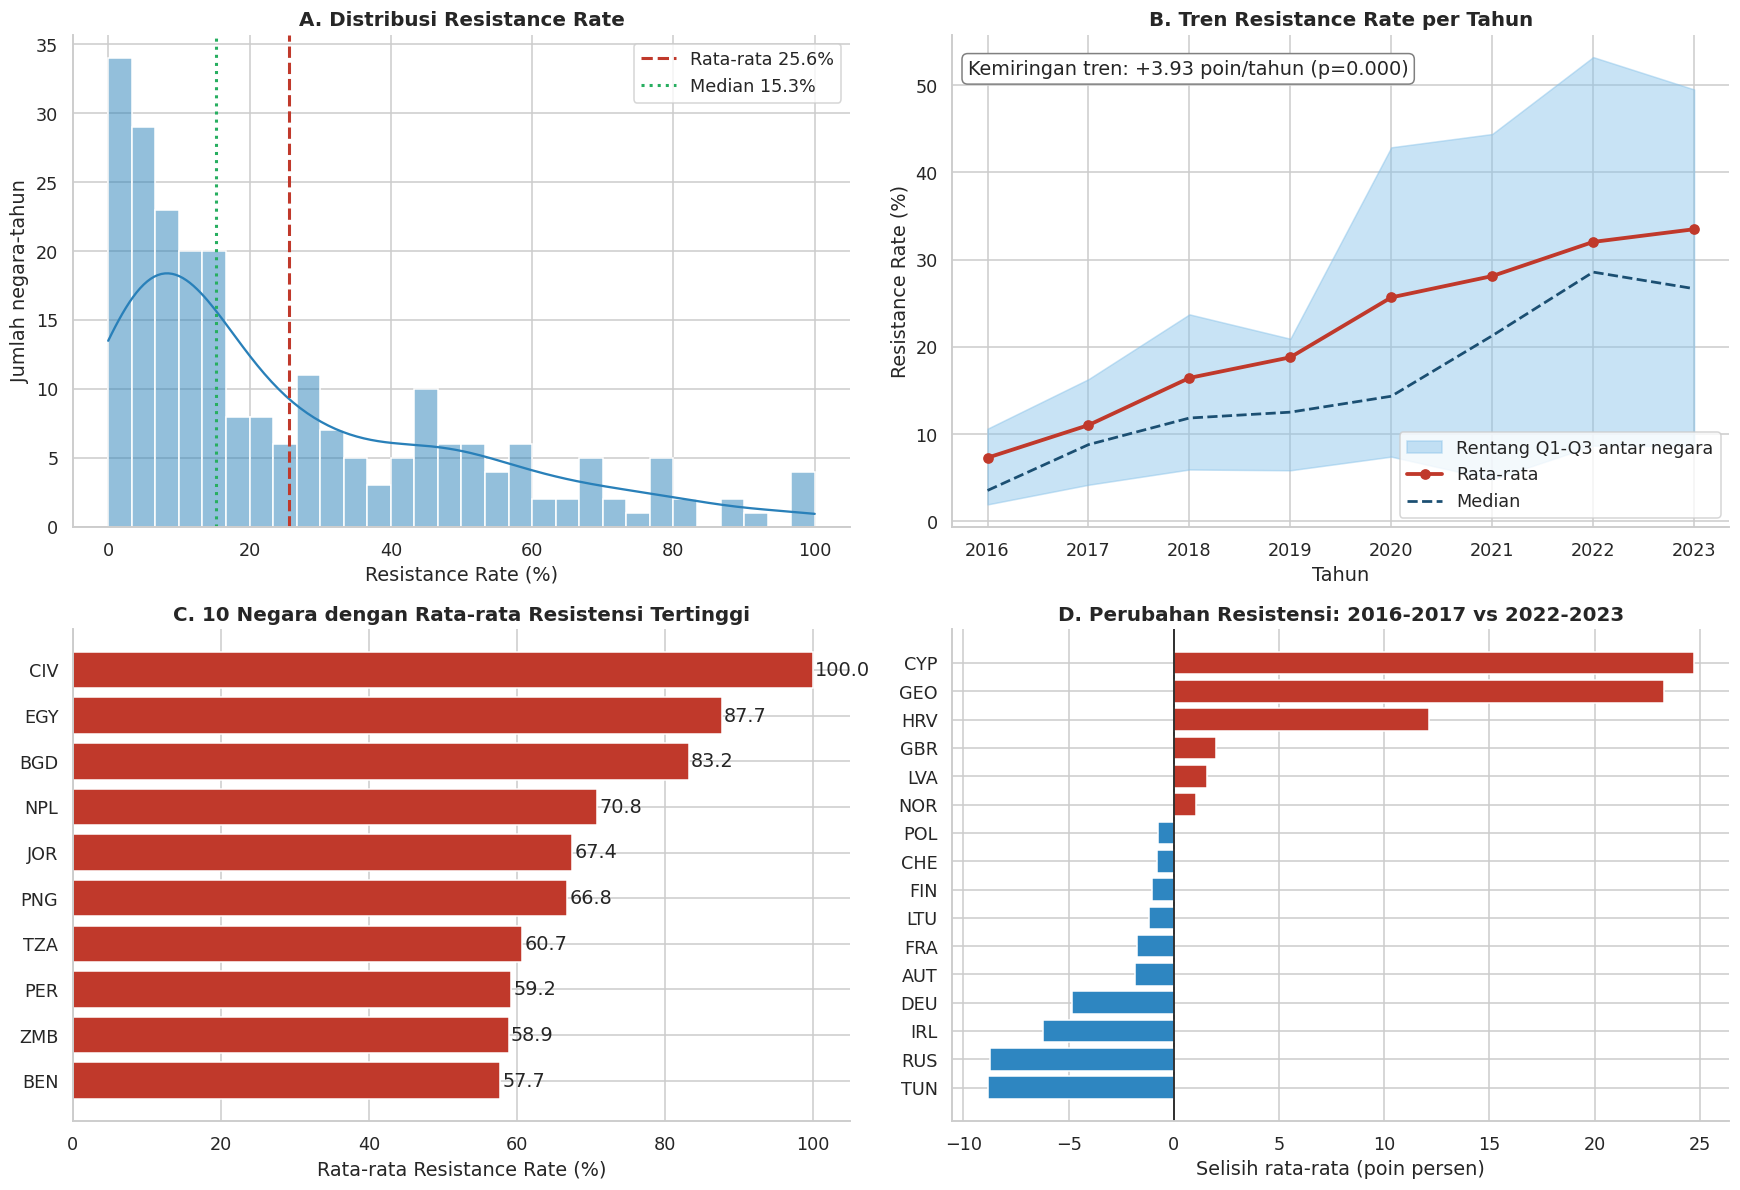

Rata-rata 25.6% | median 15.3% | rentang 0.0-100.0% | skewness 1.15
38% negara mengalami kenaikan resistensi antara dua jendela waktu.


In [ ]:
yearly = df.groupby("year")[TARGET].agg(
    mean="mean", median="median",
    q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75), n="count").reset_index()
slope, intercept, r_trend, p_trend, _ = stats.linregress(yearly["year"], yearly["mean"])

years_sorted = sorted(df["year"].unique())
k = max(1, min(3, len(years_sorted) // 3))
first_years, last_years = years_sorted[:k], years_sorted[-k:]
m_first = df[df.year.isin(first_years)].groupby("country")[TARGET].mean()
m_last = df[df.year.isin(last_years)].groupby("country")[TARGET].mean()
change = (m_last - m_first).dropna().sort_values()

country_mean = df.groupby("country")[TARGET].mean().sort_values(ascending=False)

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

ax = axes[0, 0]
sns.histplot(df[TARGET], bins=30, kde=True, color="#2980b9", ax=ax)
ax.axvline(df[TARGET].mean(), color="#c0392b", ls="--", lw=2, label=f"Rata-rata {df[TARGET].mean():.1f}%")
ax.axvline(df[TARGET].median(), color="#27ae60", ls=":", lw=2, label=f"Median {df[TARGET].median():.1f}%")
ax.set(title="A. Distribusi Resistance Rate", xlabel="Resistance Rate (%)", ylabel="Jumlah negara-tahun")
ax.legend()

ax = axes[0, 1]
ax.fill_between(yearly["year"], yearly["q25"], yearly["q75"], color="#85c1e9", alpha=0.45, label="Rentang Q1-Q3 antar negara")
ax.plot(yearly["year"], yearly["mean"], marker="o", color="#c0392b", lw=2.5, label="Rata-rata")
ax.plot(yearly["year"], yearly["median"], ls="--", color="#1b4f72", lw=1.8, label="Median")
ax.set(title="B. Tren Resistance Rate per Tahun", xlabel="Tahun", ylabel="Resistance Rate (%)")
ax.text(0.02, 0.95, f"Kemiringan tren: {slope:+.2f} poin/tahun (p={p_trend:.3f})", transform=ax.transAxes,
        va="top", bbox=dict(boxstyle="round", fc="white", ec="grey"))
ax.legend(loc="lower right")

ax = axes[1, 0]
top10 = country_mean.head(10)[::-1]
ax.barh(top10.index, top10.values, color="#c0392b")
for i, v in enumerate(top10.values):
    ax.text(v + 0.3, i, f"{v:.1f}", va="center")
ax.set(title="C. 10 Negara dengan Rata-rata Resistensi Tertinggi", xlabel="Rata-rata Resistance Rate (%)")

ax = axes[1, 1]
sel = pd.concat([change.head(8), change.tail(8)])
ax.barh(sel.index, sel.values, color=["#2e86c1" if v < 0 else "#c0392b" for v in sel.values])
ax.axvline(0, color="black", lw=1)
ax.set(title=f"D. Perubahan Resistensi: {first_years[0]}-{first_years[-1]} vs {last_years[0]}-{last_years[-1]}",
       xlabel="Selisih rata-rata (poin persen)")
plt.tight_layout(); plt.show()

q1 = dict(
    mean=df[TARGET].mean(), median=df[TARGET].median(), std=df[TARGET].std(),
    minv=df[TARGET].min(), maxv=df[TARGET].max(), skew=df[TARGET].skew(),
    slope=slope, p_trend=p_trend,
    year_first=int(yearly.year.iloc[0]), year_last=int(yearly.year.iloc[-1]),
    mean_first=yearly["mean"].iloc[0], mean_last=yearly["mean"].iloc[-1],
    pct_up=(change > 0).mean() * 100, n_change=len(change),
    top_country=country_mean.index[0], top_value=country_mean.iloc[0],
    top3=list(country_mean.head(3).index),
    top_up=list(change.tail(3).index[::-1]), top_up_val=list(change.tail(3).values[::-1]),
    first_window=(first_years[0], first_years[-1]), last_window=(last_years[0], last_years[-1]),
)
print(f"Rata-rata {q1['mean']:.1f}% | median {q1['median']:.1f}% | rentang {q1['minv']:.1f}-{q1['maxv']:.1f}% | skewness {q1['skew']:.2f}")
print(f"{q1['pct_up']:.0f}% negara mengalami kenaikan resistensi antara dua jendela waktu.")

### 5.2 Q2 – Penggunaan antibiotik, komposisi AWaRe, dan resistensi
Analisis ini sengaja memisahkan dua pertanyaan yang sering tercampur: *apakah negara yang memakai lebih banyak antibiotik lebih resisten* (**antar negara**), dan *apakah resistensi naik ketika sebuah negara menaikkan pemakaiannya* (**di dalam negara**). Pada panel B dan C, setiap titik adalah negara (B) atau penyimpangan terhadap rata-rata negaranya sendiri (C). Jika tandanya berbeda, itu pertanda efek komposisi negara (*Simpson's paradox*).

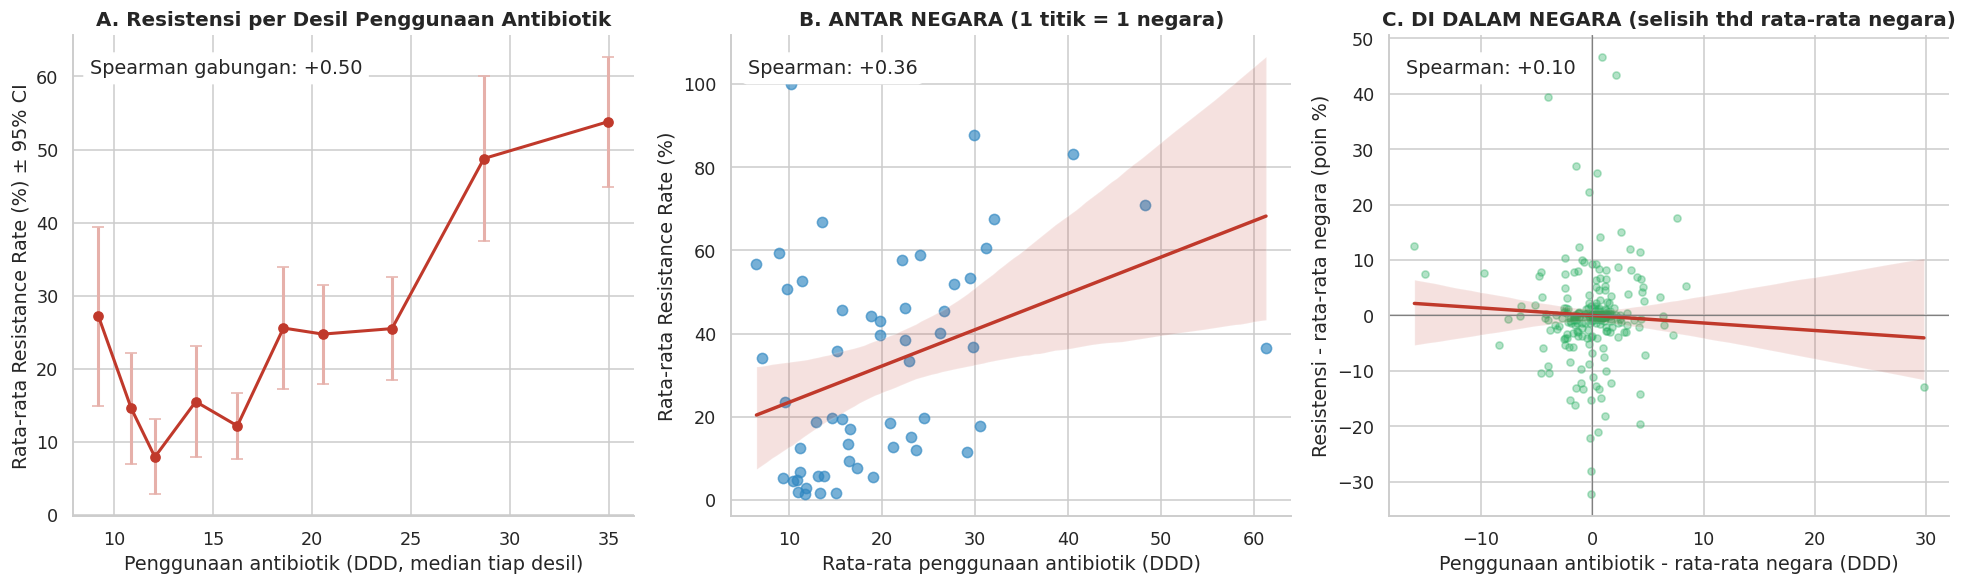

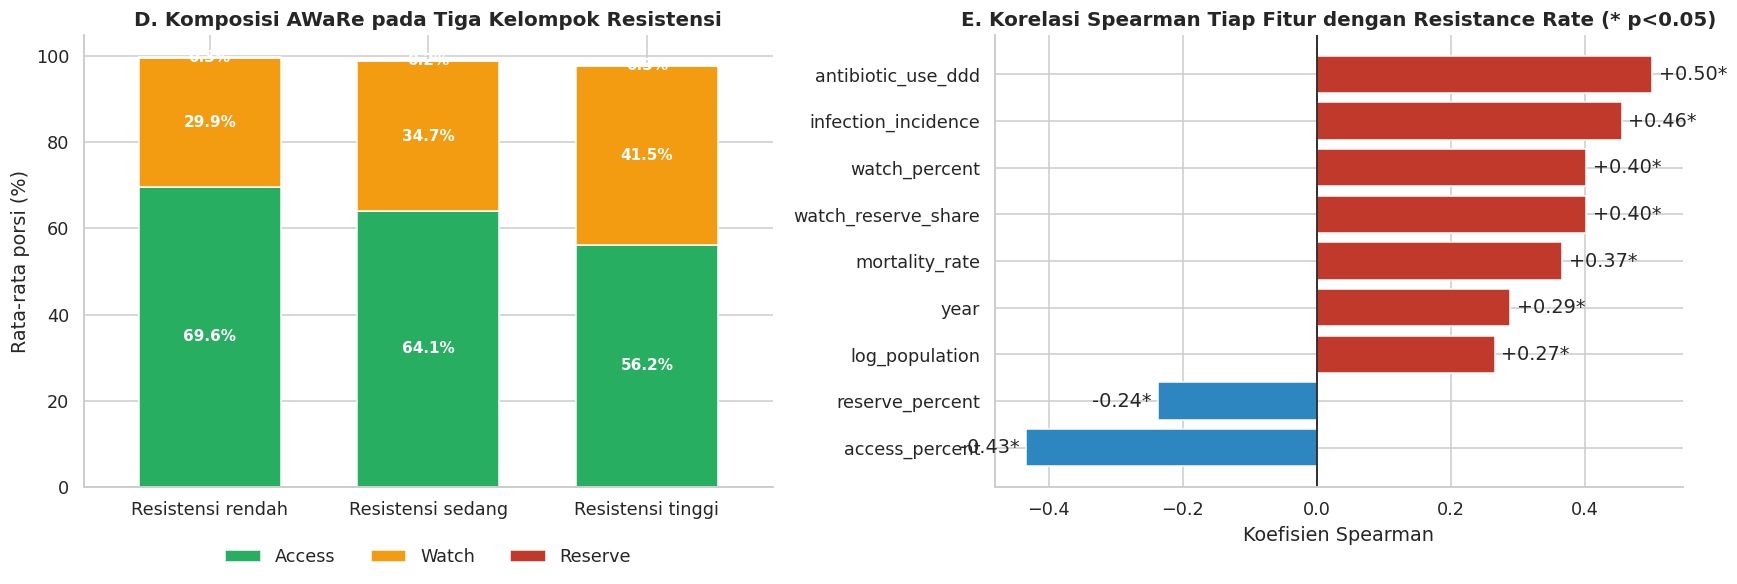

,fitur,spearman,p_value
0,access_percent,-0.434,0.000
1,reserve_percent,-0.236,0.000
2,log_population,0.266,0.000
3,year,0.288,0.000
4,mortality_rate,0.366,0.000
5,watch_reserve_share,0.402,0.000
6,watch_percent,0.403,0.000
7,infection_incidence,0.455,0.000
8,antibiotic_use_ddd,0.500,0.000


In [ ]:
def spearman(x, y):
    d = pd.concat([x, y], axis=1).dropna()
    r, p = stats.spearmanr(d.iloc[:, 0], d.iloc[:, 1])
    return r, p


def within(col):
    return df[col] - df.groupby("country")[col].transform("mean")


use_bins = pd.qcut(df["antibiotic_use_ddd"], q=10, duplicates="drop")
bin_stats = df.groupby(use_bins, observed=True).agg(
    use_med=("antibiotic_use_ddd", "median"), res_mean=(TARGET, "mean"),
    res_sem=(TARGET, "sem"), n=(TARGET, "size")).reset_index(drop=True)

cm = df.groupby("country")[["antibiotic_use_ddd", TARGET]].mean()
wdf = pd.DataFrame({"use_within": within("antibiotic_use_ddd"), "res_within": within(TARGET)})

r_pool, p_pool = spearman(df["antibiotic_use_ddd"], df[TARGET])
r_btw, p_btw = spearman(cm["antibiotic_use_ddd"], cm[TARGET])
r_wth, p_wth = spearman(wdf["use_within"], wdf["res_within"])

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
ax = axes[0]
ax.errorbar(bin_stats["use_med"], bin_stats["res_mean"], yerr=1.96 * bin_stats["res_sem"], fmt="-o",
            color="#c0392b", ecolor="#e6b0aa", capsize=4, lw=2)
ax.set(title="A. Resistensi per Desil Penggunaan Antibiotik", xlabel="Penggunaan antibiotik (DDD, median tiap desil)",
       ylabel="Rata-rata Resistance Rate (%) ± 95% CI")
ax.text(0.03, 0.95, f"Spearman gabungan: {r_pool:+.2f}", transform=ax.transAxes, va="top", bbox=dict(boxstyle="round", fc="white"))

ax = axes[1]
sns.regplot(data=cm, x="antibiotic_use_ddd", y=TARGET, scatter_kws=dict(alpha=0.65, s=45, color="#2e86c1"),
            line_kws=dict(color="#c0392b"), ax=ax)
ax.set(title="B. ANTAR NEGARA (1 titik = 1 negara)", xlabel="Rata-rata penggunaan antibiotik (DDD)", ylabel="Rata-rata Resistance Rate (%)")
ax.text(0.03, 0.95, f"Spearman: {r_btw:+.2f}", transform=ax.transAxes, va="top", bbox=dict(boxstyle="round", fc="white"))

ax = axes[2]
sns.regplot(data=wdf, x="use_within", y="res_within", scatter_kws=dict(alpha=0.35, s=22, color="#27ae60"),
            line_kws=dict(color="#c0392b"), ax=ax)
ax.axhline(0, color="grey", lw=0.8); ax.axvline(0, color="grey", lw=0.8)
ax.set(title="C. DI DALAM NEGARA (selisih thd rata-rata negara)", xlabel="Penggunaan antibiotik - rata-rata negara (DDD)",
       ylabel="Resistensi - rata-rata negara (poin %)")
ax.text(0.03, 0.95, f"Spearman: {r_wth:+.2f}", transform=ax.transAxes, va="top", bbox=dict(boxstyle="round", fc="white"))
plt.tight_layout(); plt.show()

# --- Komposisi AWaRe menurut tingkat resistensi
tert = pd.qcut(df[TARGET], 3, labels=["Resistensi rendah", "Resistensi sedang", "Resistensi tinggi"])
comp = df.groupby(tert, observed=True)[["access_percent", "watch_percent", "reserve_percent"]].mean()

feat_list = ["antibiotic_use_ddd", "access_percent", "watch_percent", "reserve_percent", "watch_reserve_share",
             "infection_incidence", "mortality_rate", "log_population", "year"]
sp_rows = []
for f in feat_list:
    r, p = spearman(df[f], df[TARGET])
    sp_rows.append({"fitur": f, "spearman": r, "p_value": p})
sp_df = pd.DataFrame(sp_rows).sort_values("spearman")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
ax = axes[0]
comp.plot(kind="bar", stacked=True, color=["#27ae60", "#f39c12", "#c0392b"], ax=ax, width=0.65)
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", label_type="center", color="white", fontsize=10, fontweight="bold")
ax.set(title="D. Komposisi AWaRe pada Tiga Kelompok Resistensi", xlabel="", ylabel="Rata-rata porsi (%)")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(["Access", "Watch", "Reserve"], loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)

ax = axes[1]
ax.barh(sp_df["fitur"], sp_df["spearman"], color=["#2e86c1" if v < 0 else "#c0392b" for v in sp_df["spearman"]])
ax.axvline(0, color="black", lw=1)
for i, (v, p) in enumerate(zip(sp_df["spearman"], sp_df["p_value"])):
    ax.text(v + (0.01 if v >= 0 else -0.01), i, f"{v:+.2f}{'*' if p < 0.05 else ''}", va="center", ha="left" if v >= 0 else "right")
ax.set(title="E. Korelasi Spearman Tiap Fitur dengan Resistance Rate (* p<0.05)", xlabel="Koefisien Spearman")
plt.tight_layout(); plt.show()

sp_map = sp_df.set_index("fitur")["spearman"].to_dict()
q2 = dict(r_pool=r_pool, p_pool=p_pool, r_btw=r_btw, p_btw=p_btw, r_wth=r_wth, p_wth=p_wth,
          r_access=sp_map["access_percent"], r_watch=sp_map["watch_percent"], r_reserve=sp_map["reserve_percent"],
          r_wr=sp_map["watch_reserve_share"],
          access_low=comp.iloc[0]["access_percent"], access_high=comp.iloc[-1]["access_percent"],
          wr_low=comp.iloc[0][["watch_percent", "reserve_percent"]].sum(), wr_high=comp.iloc[-1][["watch_percent", "reserve_percent"]].sum())
display(sp_df.reset_index(drop=True))

### 5.3 Q3 (bagian EDA) – Beban epidemiologis dan resistensi
Panel kiri: tiap gelembung adalah satu negara (ukuran = populasi, warna = mortalitas infeksi per 100.000). Panel kanan: peta panas 15 negara dengan resistensi tertinggi sepanjang tahun, untuk melihat apakah resistensi tinggi itu **menetap** atau hanya lonjakan sesaat. Bagian kedua Q3 (negara di atas prediksi) dijawab setelah pemodelan.

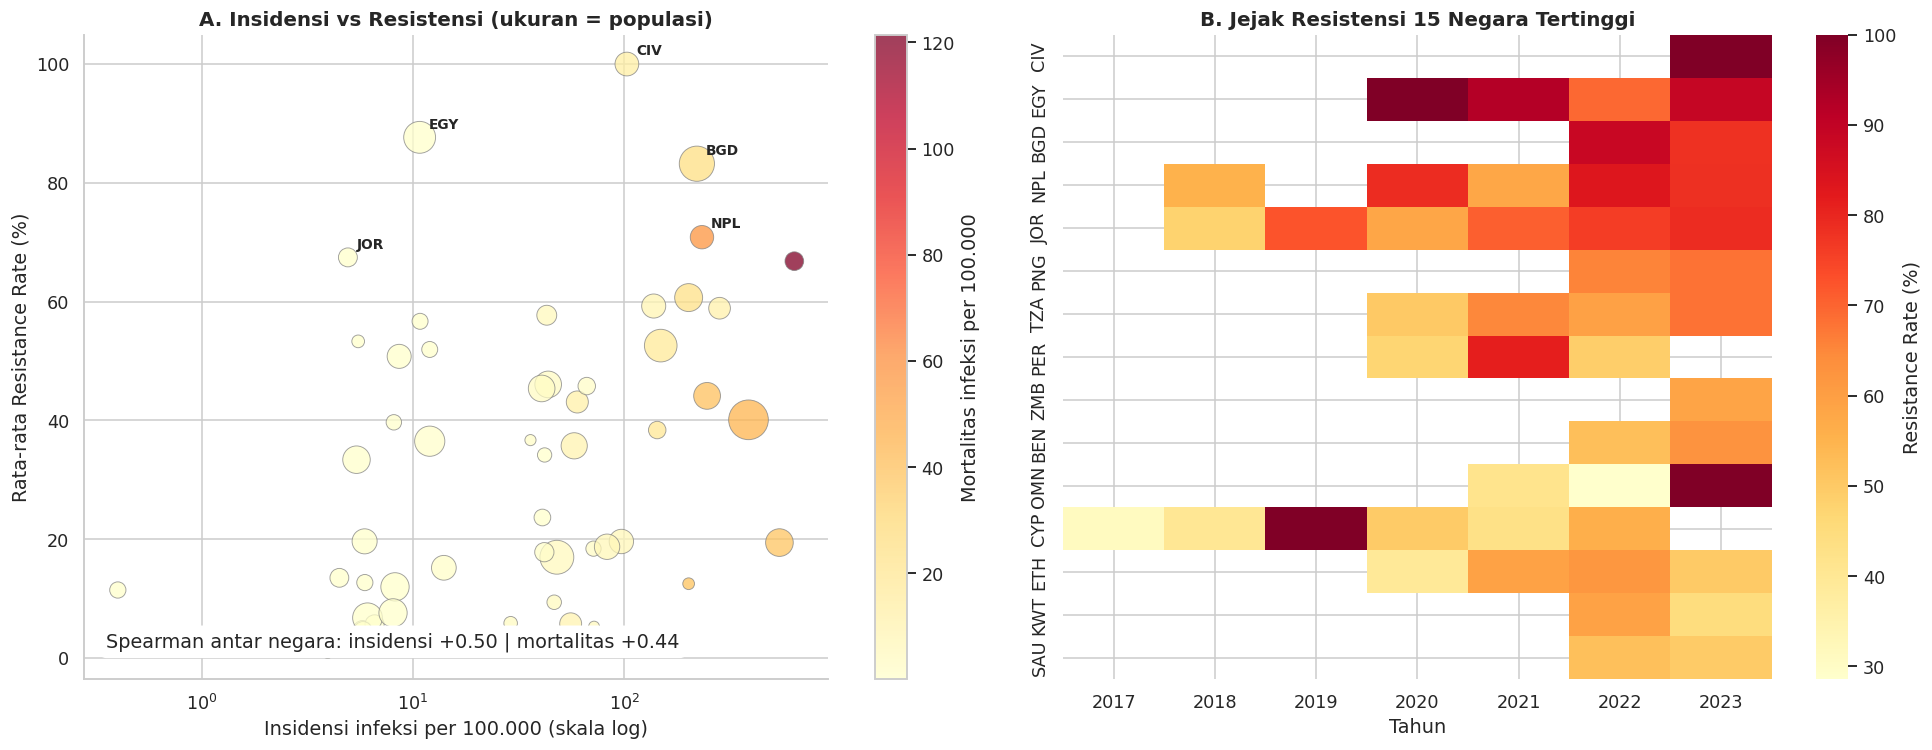

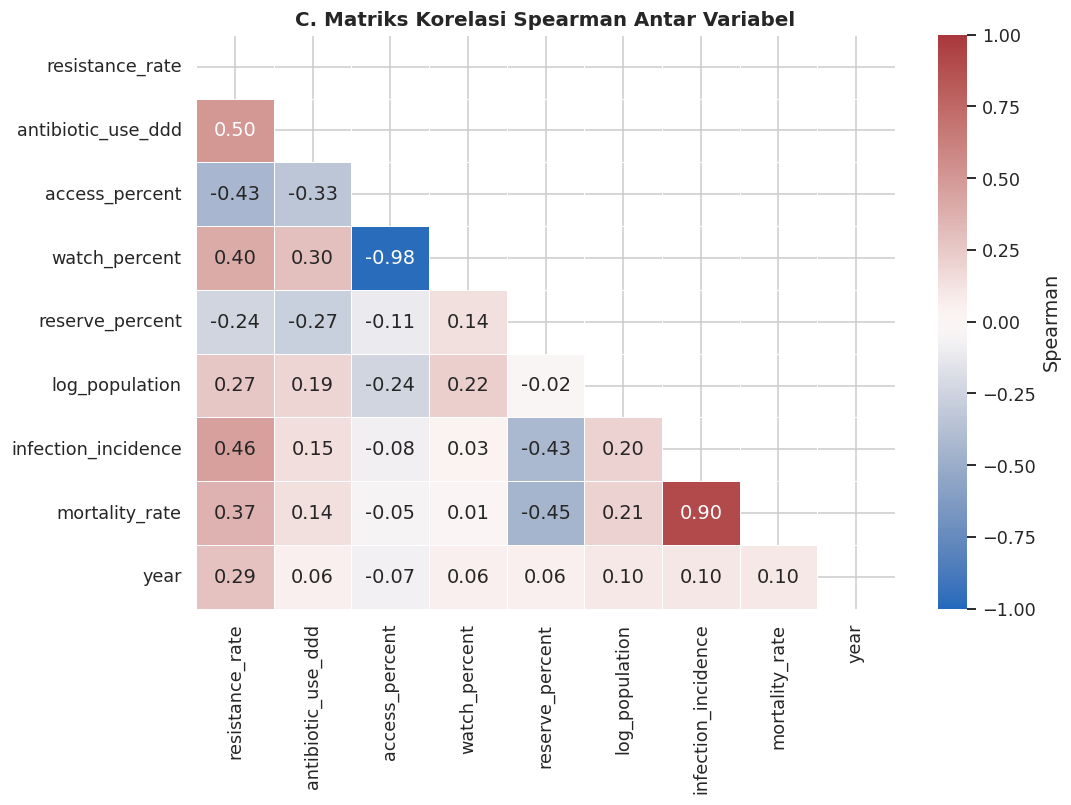

In [ ]:
cty = df.groupby("country").agg(res=(TARGET, "mean"), inc=("infection_incidence", "mean"),
                                mort=("mortality_rate", "mean"), pop=("population", "mean")).reset_index()
r_inc_pool, _ = spearman(df["infection_incidence"], df[TARGET])
r_mort_pool, _ = spearman(df["mortality_rate"], df[TARGET])
r_inc_btw, _ = spearman(cty["inc"], cty["res"])
r_mort_btw, _ = spearman(cty["mort"], cty["res"])
r_inc_wth, _ = spearman(within("infection_incidence"), within(TARGET))

fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={"width_ratios": [1.05, 1]})
ax = axes[0]
sizes = np.sqrt(cty["pop"] / cty["pop"].max()) * 650 + 25
sc = ax.scatter(cty["inc"], cty["res"], s=sizes, c=cty["mort"], cmap="YlOrRd", alpha=0.75, edgecolor="grey", linewidth=0.6)
if (cty["inc"] > 0).all():
    ax.set_xscale("log")
for _, r in cty.nlargest(5, "res").iterrows():
    ax.annotate(r["country"], (r["inc"], r["res"]), xytext=(6, 6), textcoords="offset points", fontsize=9, fontweight="bold")
cb = plt.colorbar(sc, ax=ax); cb.set_label("Mortalitas infeksi per 100.000")
ax.set(title="A. Insidensi vs Resistensi (ukuran = populasi)", xlabel="Insidensi infeksi per 100.000 (skala log)", ylabel="Rata-rata Resistance Rate (%)")
ax.text(0.03, 0.05, f"Spearman antar negara: insidensi {r_inc_btw:+.2f} | mortalitas {r_mort_btw:+.2f}",
        transform=ax.transAxes, bbox=dict(boxstyle="round", fc="white"))

ax = axes[1]
top15 = cty.nlargest(15, "res")["country"].tolist()
pv = df[df.country.isin(top15)].pivot_table(index="country", columns="year", values=TARGET).reindex(top15)
sns.heatmap(pv, cmap="YlOrRd", ax=ax, cbar_kws={"label": "Resistance Rate (%)"}, xticklabels=max(1, pv.shape[1] // 12))
ax.set(title="B. Jejak Resistensi 15 Negara Tertinggi", xlabel="Tahun", ylabel="")
plt.tight_layout(); plt.show()

num_cols = [TARGET, "antibiotic_use_ddd", "access_percent", "watch_percent", "reserve_percent",
            "log_population", "infection_incidence", "mortality_rate", "year"]
corr = df[num_cols].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(10, 7.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, linewidths=0.5,
            cbar_kws={"label": "Spearman"})
plt.title("C. Matriks Korelasi Spearman Antar Variabel")
plt.tight_layout(); plt.show()

q3 = dict(r_inc_pool=r_inc_pool, r_mort_pool=r_mort_pool, r_inc_btw=r_inc_btw, r_mort_btw=r_mort_btw, r_inc_wth=r_inc_wth)

## 6. Pemodelan Regresi

**Strategi validasi.** Pada data panel negara–tahun, pembagian acak membuat baris negara yang sama muncul di data latih dan uji sehingga skor terlalu optimis. Karena tujuan surveilans adalah memprediksi negara yang belum pernah dilihat, model dibandingkan dengan dua skema: **KFold acak** dan **GroupKFold per negara**. Selisih keduanya mengukur seberapa besar skor dipengaruhi kebocoran antar-baris negara yang sama.

Data model: 237 baris, 8 fitur, 56 negara, 5-fold


R2                              MAE  \
skema                GroupKFold per negara KFold acak GroupKFold per negara   
model                                                                         
Baseline (rata-rata)                -0.356     -0.016                20.746   
Gradient Boosting                   -0.028      0.648                17.840   
Random Forest                        0.097      0.644                16.779   
Ridge                               -0.303      0.305                18.421   

                                                 RMSE             
skema                KFold acak GroupKFold per negara KFold acak  
model                                                             
Baseline (rata-rata)     20.361                25.059     24.602  
Gradient Boosting        10.221                22.631     14.471  
Random Forest            10.110                21.373     14.612  
Ridge                    15.337                24.390     20.321

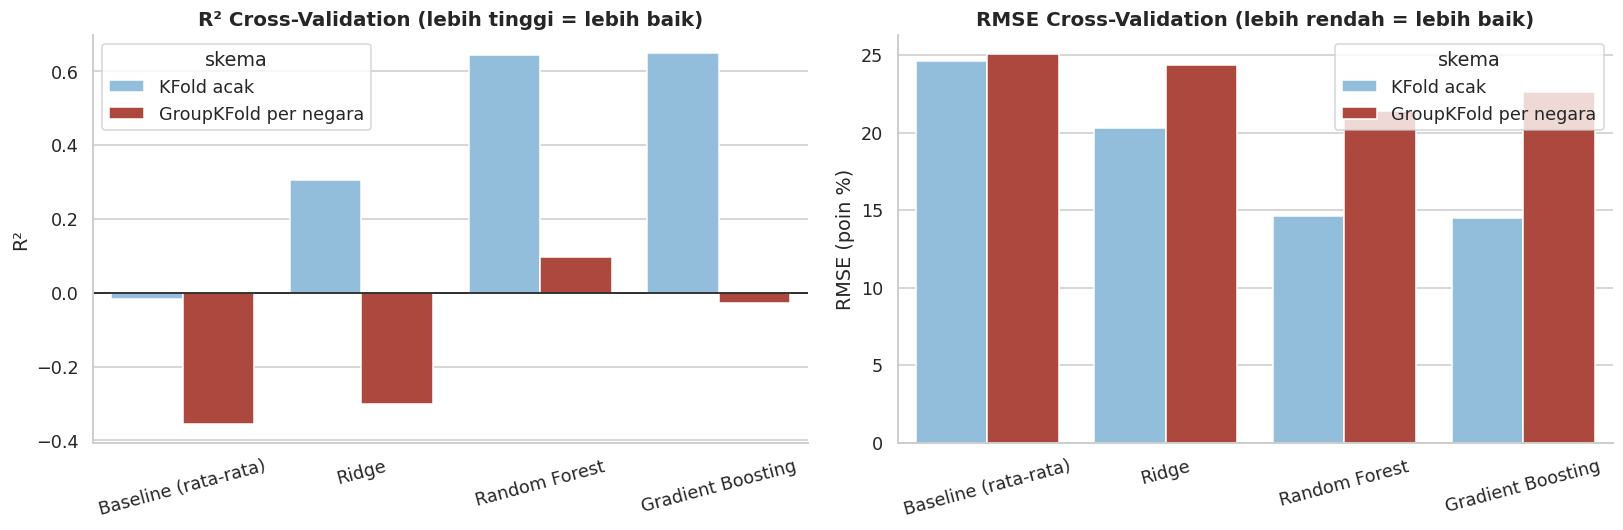

Model terbaik pada skema per negara: Random Forest


In [ ]:
FEATURES = ["antibiotic_use_ddd", "access_percent", "watch_percent", "reserve_percent",
            "log_population", "infection_incidence", "mortality_rate", "year"]

model_df = df.dropna(subset=FEATURES + [TARGET]).reset_index(drop=True)
X, y, groups = model_df[FEATURES], model_df[TARGET], model_df["country"]
N_SPLITS = int(min(5, groups.nunique()))
print(f"Data model: {X.shape[0]:,} baris, {X.shape[1]} fitur, {groups.nunique()} negara, {N_SPLITS}-fold")

models = {
    "Baseline (rata-rata)": Pipeline([("model", DummyRegressor(strategy="mean"))]),
    "Ridge": Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=1.0))]),
    "Random Forest": Pipeline([("model", RandomForestRegressor(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE))]),
    "Gradient Boosting": Pipeline([("model", GradientBoostingRegressor(random_state=RANDOM_STATE))]),
}
schemes = {
    "KFold acak": (KFold(N_SPLITS, shuffle=True, random_state=RANDOM_STATE), None),
    "GroupKFold per negara": (GroupKFold(N_SPLITS), groups),
}
scoring = {"r2": "r2", "mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error"}

rows = []
for mname, est in models.items():
    for sname, (cv, grp) in schemes.items():
        res = cross_validate(est, X, y, cv=cv, groups=grp, scoring=scoring, n_jobs=-1)
        rows.append({"model": mname, "skema": sname,
                     "R2": res["test_r2"].mean(), "R2_std": res["test_r2"].std(),
                     "MAE": -res["test_mae"].mean(), "RMSE": -res["test_rmse"].mean()})
cv_table = pd.DataFrame(rows)
display(cv_table.pivot(index="model", columns="skema", values=["R2", "MAE", "RMSE"]))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=cv_table, x="model", y="R2", hue="skema", palette=["#85c1e9", "#c0392b"], ax=axes[0])
axes[0].set(title="R² Cross-Validation (lebih tinggi = lebih baik)", xlabel="", ylabel="R²")
axes[0].axhline(0, color="black", lw=1)
sns.barplot(data=cv_table, x="model", y="RMSE", hue="skema", palette=["#85c1e9", "#c0392b"], ax=axes[1])
axes[1].set(title="RMSE Cross-Validation (lebih rendah = lebih baik)", xlabel="", ylabel="RMSE (poin %)")
for a in axes:
    a.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

cand = cv_table[(cv_table.skema == "GroupKFold per negara") & (cv_table.model != "Baseline (rata-rata)")]
best_name = cand.sort_values("R2", ascending=False).iloc[0]["model"]
print(f"Model terbaik pada skema per negara: {best_name}")

### 6.1 Tuning dan Evaluasi Hold-out (negara uji tidak pernah dilihat saat latih)

Latih: 176 baris (44 negara) | Uji: 61 baris (12 negara)
Parameter terbaik: {'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__n_estimators': 400}


,R2,MAE,RMSE
Baseline (rata-rata),-1.768,19.843,21.292
Random Forest (tuned),-1.974,17.656,22.072


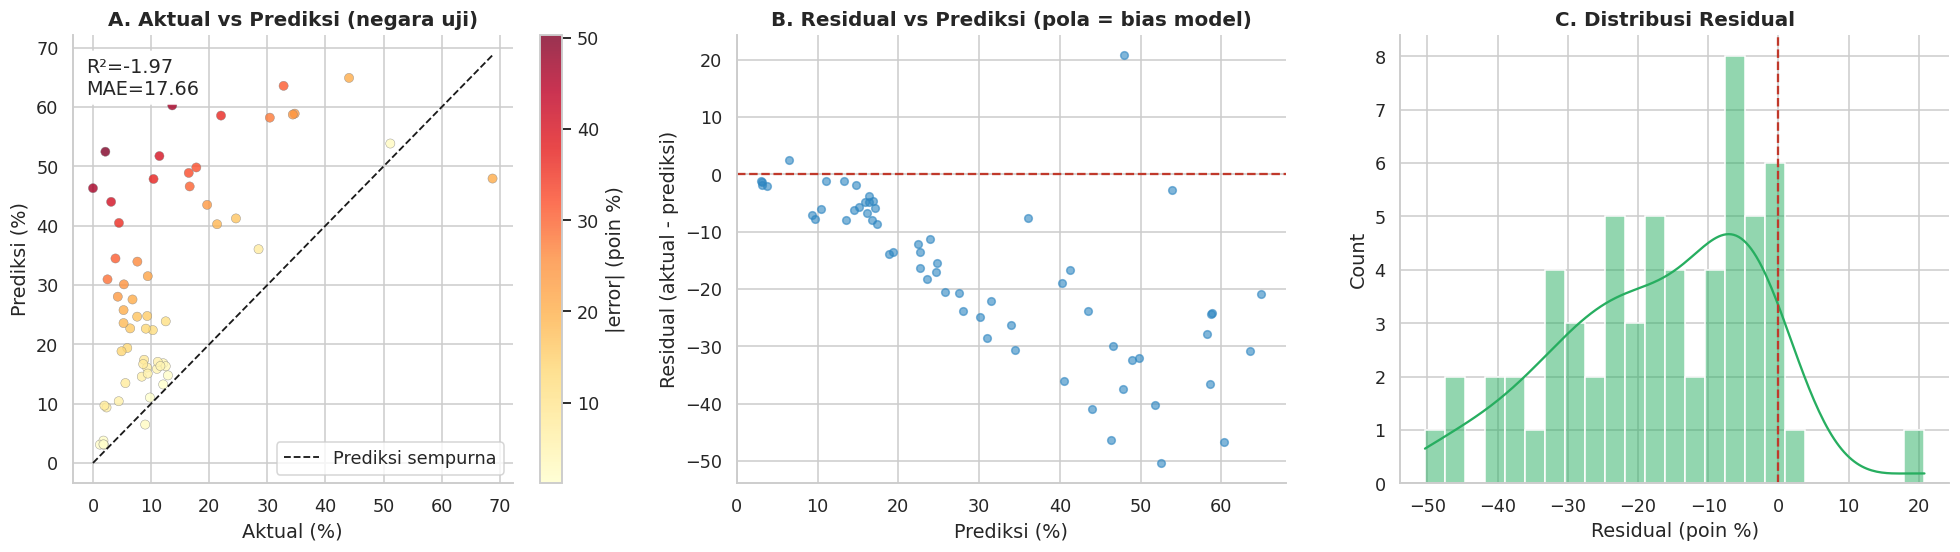

In [ ]:
PARAM_GRIDS = {
    "Ridge": {"model__alpha": [0.01, 0.1, 1, 10, 100]},
    "Random Forest": {"model__n_estimators": [200, 400], "model__max_depth": [None, 10], "model__min_samples_leaf": [1, 3]},
    "Gradient Boosting": {"model__n_estimators": [150, 300], "model__learning_rate": [0.05, 0.1], "model__max_depth": [2, 3]},
}

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
tr_idx, te_idx = next(gss.split(X, y, groups))
X_tr, X_te, y_tr, y_te = X.iloc[tr_idx], X.iloc[te_idx], y.iloc[tr_idx], y.iloc[te_idx]
g_tr = groups.iloc[tr_idx]
print(f"Latih: {len(X_tr):,} baris ({g_tr.nunique()} negara) | Uji: {len(X_te):,} baris ({groups.iloc[te_idx].nunique()} negara)")

grid = GridSearchCV(models[best_name], PARAM_GRIDS[best_name], cv=GroupKFold(min(N_SPLITS, g_tr.nunique())),
                    scoring="neg_root_mean_squared_error", n_jobs=-1)
grid.fit(X_tr, y_tr, groups=g_tr)
best_model = grid.best_estimator_
print("Parameter terbaik:", grid.best_params_)


def metrics(y_true, y_hat):
    return {"R2": r2_score(y_true, y_hat), "MAE": mean_absolute_error(y_true, y_hat),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_hat))}


base = clone(models["Baseline (rata-rata)"]).fit(X_tr, y_tr)
y_pred = best_model.predict(X_te)
hold = pd.DataFrame({"Baseline (rata-rata)": metrics(y_te, base.predict(X_te)), f"{best_name} (tuned)": metrics(y_te, y_pred)}).T
display(hold)

resid = y_te - y_pred
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
ax = axes[0]
lim = [min(y_te.min(), y_pred.min()), max(y_te.max(), y_pred.max())]
sc = ax.scatter(y_te, y_pred, c=np.abs(resid), cmap="YlOrRd", alpha=0.8, edgecolor="grey", linewidth=0.3)
ax.plot(lim, lim, "k--", lw=1.2, label="Prediksi sempurna")
plt.colorbar(sc, ax=ax, label="|error| (poin %)")
ax.set(title="A. Aktual vs Prediksi (negara uji)", xlabel="Aktual (%)", ylabel="Prediksi (%)")
ax.text(0.03, 0.95, f"R²={hold.iloc[1]['R2']:.2f}\nMAE={hold.iloc[1]['MAE']:.2f}", transform=ax.transAxes, va="top", bbox=dict(boxstyle="round", fc="white"))
ax.legend(loc="lower right")

ax = axes[1]
ax.scatter(y_pred, resid, alpha=0.6, color="#2e86c1", s=25)
ax.axhline(0, color="#c0392b", ls="--")
ax.set(title="B. Residual vs Prediksi (pola = bias model)", xlabel="Prediksi (%)", ylabel="Residual (aktual - prediksi)")

ax = axes[2]
sns.histplot(resid, kde=True, bins=25, color="#27ae60", ax=ax)
ax.axvline(0, color="#c0392b", ls="--")
ax.set(title="C. Distribusi Residual", xlabel="Residual (poin %)")
plt.tight_layout(); plt.show()

### 6.2 Interpretasi Model: fitur apa yang paling berpengaruh dan bagaimana bentuk pengaruhnya?

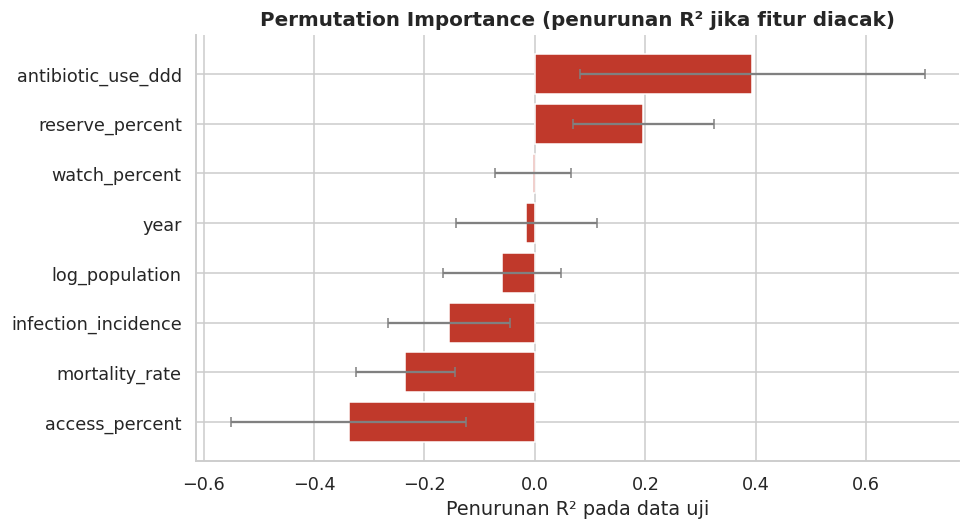

,fitur,penurunan_R2,std
0,antibiotic_use_ddd,0.394,0.312
1,reserve_percent,0.196,0.128
2,watch_percent,-0.003,0.069
3,year,-0.015,0.128
4,log_population,-0.060,0.107
5,infection_incidence,-0.156,0.110
6,mortality_rate,-0.235,0.090
7,access_percent,-0.338,0.213


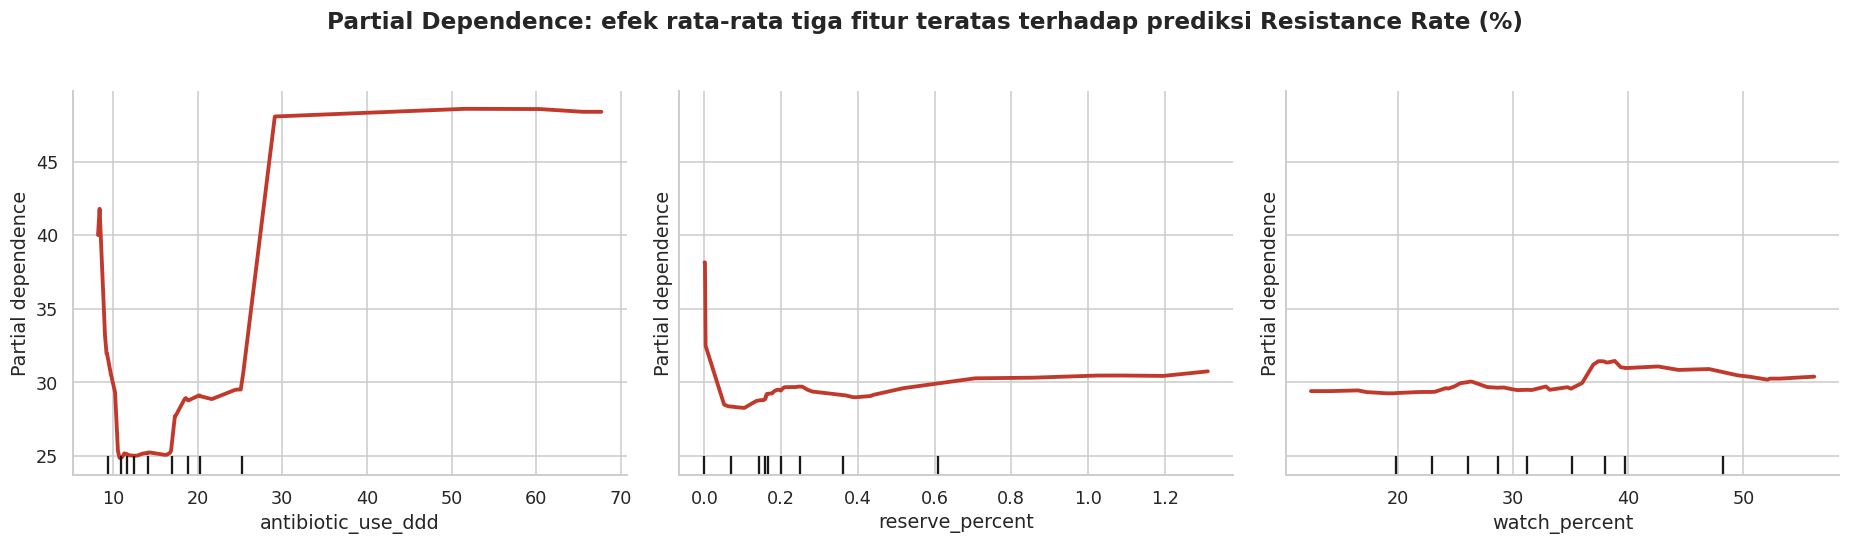

In [ ]:
perm = permutation_importance(best_model, X_te, y_te, n_repeats=20, random_state=RANDOM_STATE, scoring="r2", n_jobs=-1)
imp = pd.DataFrame({"fitur": FEATURES, "penurunan_R2": perm.importances_mean, "std": perm.importances_std}).sort_values("penurunan_R2")

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(imp["fitur"], imp["penurunan_R2"], xerr=imp["std"], color="#c0392b", ecolor="grey", capsize=3)
ax.set(title="Permutation Importance (penurunan R² jika fitur diacak)", xlabel="Penurunan R² pada data uji")
plt.tight_layout(); plt.show()
display(imp.sort_values("penurunan_R2", ascending=False).reset_index(drop=True))

top_feats = imp.sort_values("penurunan_R2", ascending=False)["fitur"].head(3).tolist()
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
PartialDependenceDisplay.from_estimator(best_model, X_te, top_feats, kind="average", ax=axes,
                                        line_kw={"color": "#c0392b", "lw": 2.5})
fig.suptitle("Partial Dependence: efek rata-rata tiga fitur teratas terhadap prediksi Resistance Rate (%)", fontweight="bold", y=1.03)
plt.tight_layout(); plt.show()

q4 = dict(best_name=best_name, params=grid.best_params_,
          r2_hold=hold.iloc[1]["R2"], mae_hold=hold.iloc[1]["MAE"], rmse_hold=hold.iloc[1]["RMSE"],
          r2_base=hold.iloc[0]["R2"], rmse_base=hold.iloc[0]["RMSE"],
          r2_grp=cv_table[(cv_table.model == best_name) & (cv_table.skema == "GroupKFold per negara")]["R2"].iloc[0],
          r2_rnd=cv_table[(cv_table.model == best_name) & (cv_table.skema == "KFold acak")]["R2"].iloc[0],
          top_feats=top_feats,
          top_feat_drop=imp.sort_values("penurunan_R2", ascending=False)["penurunan_R2"].head(3).tolist())

### 6.3 Q3 (bagian pemodelan) – Negara dengan resistensi jauh di atas prediksi
Prediksi *out-of-fold* (GroupKFold) dibuat untuk **setiap** negara oleh model yang tidak pernah melihat negara tersebut. Residual positif berarti resistensi aktual **lebih tinggi** dari yang dijelaskan oleh penggunaan antibiotik dan faktor epidemiologis, sehingga ada faktor lain yang bekerja (misalnya pengendalian infeksi, kualitas layanan, penggunaan di luar sektor manusia) dan negara itu layak diprioritaskan untuk surveilans.

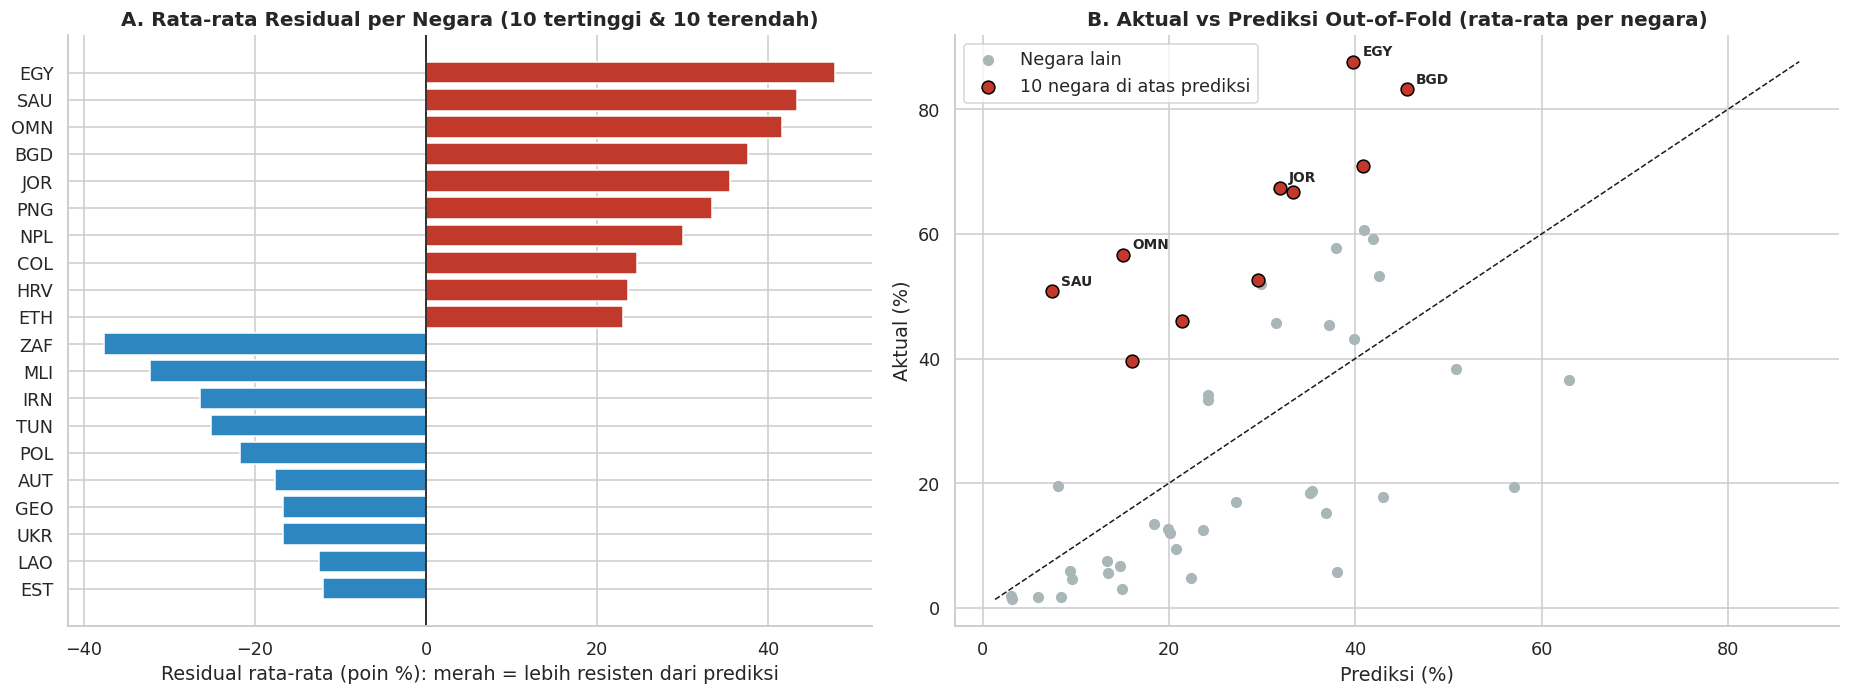

,country,residual,n,actual,pred
0,EGY,47.862,4,87.660,39.798
1,SAU,43.317,2,50.775,7.458
2,OMN,41.600,3,56.677,15.077
3,BGD,37.672,2,83.215,45.543
4,JOR,35.517,6,67.442,31.925
5,PNG,33.468,2,66.805,33.337
6,NPL,29.997,5,70.842,40.845
7,COL,24.605,3,46.050,21.445
8,HRV,23.582,7,39.667,16.086
9,ETH,23.070,4,52.585,29.515


In [ ]:
oof_model = clone(best_model)
model_df["pred_oof"] = cross_val_predict(oof_model, X, y, cv=GroupKFold(N_SPLITS), groups=groups, n_jobs=-1)
model_df["residual"] = model_df[TARGET] - model_df["pred_oof"]
r2_oof = r2_score(y, model_df["pred_oof"])

min_n = 2 if model_df.groupby("country").size().max() >= 2 else 1
country_res = (model_df.groupby("country")
               .agg(residual=("residual", "mean"), n=("residual", "size"), actual=(TARGET, "mean"), pred=("pred_oof", "mean"))
               .reset_index())
country_res = country_res[country_res["n"] >= min_n]
hot = country_res.nlargest(10, "residual")
cold = country_res.nsmallest(10, "residual")

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1, 1.1]})
ax = axes[0]
sel = pd.concat([cold.sort_values("residual", ascending=False), hot.sort_values("residual")])
ax.barh(sel["country"], sel["residual"], color=["#2e86c1" if v < 0 else "#c0392b" for v in sel["residual"]])
ax.axvline(0, color="black", lw=1)
ax.set(title="A. Rata-rata Residual per Negara (10 tertinggi & 10 terendah)",
       xlabel="Residual rata-rata (poin %): merah = lebih resisten dari prediksi")

ax = axes[1]
ax.scatter(country_res["pred"], country_res["actual"], color="#aab7b8", s=40, label="Negara lain")
ax.scatter(hot["pred"], hot["actual"], color="#c0392b", s=70, label="10 negara di atas prediksi", edgecolor="black")
lim = [min(country_res["pred"].min(), country_res["actual"].min()), max(country_res["pred"].max(), country_res["actual"].max())]
ax.plot(lim, lim, "k--", lw=1)
for _, r in hot.head(5).iterrows():
    ax.annotate(r["country"], (r["pred"], r["actual"]), xytext=(6, 4), textcoords="offset points", fontsize=9, fontweight="bold")
ax.set(title="B. Aktual vs Prediksi Out-of-Fold (rata-rata per negara)", xlabel="Prediksi (%)", ylabel="Aktual (%)")
ax.legend()
plt.tight_layout(); plt.show()

display(hot.reset_index(drop=True))
q3.update(r2_oof=r2_oof, hot=list(hot["country"].head(5)), hot_val=list(hot["residual"].head(5)),
          cold=list(cold["country"].head(3)), cold_val=list(cold["residual"].head(3)))

## 7. Simpulan
Sel berikut menyusun jawaban atas keempat pertanyaan dari angka-angka hasil analisis di atas. Kalimat dan angka dihitung otomatis sehingga selalu konsisten dengan data yang dipakai.

In [ ]:
def kekuatan(r):
    a = abs(r)
    return "sangat lemah" if a < 0.1 else "lemah" if a < 0.3 else "sedang" if a < 0.5 else "kuat" if a < 0.7 else "sangat kuat"


def arah(r):
    return "positif" if r > 0 else "negatif"


def sig(p):
    return "signifikan (p<0.05)" if p < 0.05 else "tidak signifikan"


tren = "meningkat" if q1["slope"] > 0 else "menurun"
sama_arah = np.sign(q2["r_btw"]) == np.sign(q2["r_wth"])
gap = q4["r2_rnd"] - q4["r2_grp"]

print("=" * 100)
print("SIMPULAN AKHIR")
print("=" * 100)

print(f"""
Q1 (BASIC) - Distribusi dan tren resistensi
-------------------------------------------
Rata-rata resistance rate {q1['mean']:.1f}% (median {q1['median']:.1f}%, rentang {q1['minv']:.1f}-{q1['maxv']:.1f}%, skewness {q1['skew']:.2f}).
Rata-rata tahunan {tren} sekitar {abs(q1['slope']):.2f} poin persen per tahun ({sig(q1['p_trend'])}); dari {q1['mean_first']:.1f}% ({q1['year_first']}) menjadi {q1['mean_last']:.1f}% ({q1['year_last']}).
Antara {q1['first_window'][0]}-{q1['first_window'][1]} dan {q1['last_window'][0]}-{q1['last_window'][1]}, {q1['pct_up']:.0f}% dari {q1['n_change']} negara mengalami kenaikan resistensi.
Resistensi tertinggi: {', '.join(q1['top3'])} (tertinggi {q1['top_country']} dengan rata-rata {q1['top_value']:.1f}%).
Kenaikan terbesar: {', '.join(f'{n} ({v:+.1f} poin)' for n, v in zip(q1['top_up'], q1['top_up_val']))}.
""")

print(f"""Q2 (ANALISIS) - Penggunaan antibiotik, AWaRe, dan resistensi
-----------------------------------------------------------
Korelasi Spearman penggunaan antibiotik (DDD) dengan resistensi: gabungan {q2['r_pool']:+.2f} ({kekuatan(q2['r_pool'])}, {arah(q2['r_pool'])}),
antar negara {q2['r_btw']:+.2f} ({kekuatan(q2['r_btw'])}, {sig(q2['p_btw'])}), dan di dalam negara {q2['r_wth']:+.2f} ({kekuatan(q2['r_wth'])}, {sig(q2['p_wth'])}).
{'Arah hubungan sama pada kedua level.' if sama_arah else 'Arah hubungan BERBEDA antara level antar-negara dan di-dalam-negara, sehingga pola antar negara tidak boleh ditafsirkan sebagai efek perubahan pemakaian di satu negara.'}
Komposisi AWaRe: korelasi dengan resistensi untuk Access {q2['r_access']:+.2f}, Watch {q2['r_watch']:+.2f}, Reserve {q2['r_reserve']:+.2f}; porsi Watch+Reserve {q2['r_wr']:+.2f}.
Kelompok resistensi rendah memiliki porsi Access rata-rata {q2['access_low']:.1f}% dan kelompok resistensi tinggi {q2['access_high']:.1f}%
(Watch+Reserve: {q2['wr_low']:.1f}% vs {q2['wr_high']:.1f}%).
""")

print(f"""Q3 (ANALISIS) - Beban epidemiologis dan negara di atas prediksi
---------------------------------------------------------------
Insidensi infeksi vs resistensi: Spearman gabungan {q3['r_inc_pool']:+.2f}, antar negara {q3['r_inc_btw']:+.2f} ({kekuatan(q3['r_inc_btw'])}), di dalam negara {q3['r_inc_wth']:+.2f}.
Mortalitas infeksi per 100.000 vs resistensi: gabungan {q3['r_mort_pool']:+.2f}, antar negara {q3['r_mort_btw']:+.2f} ({kekuatan(q3['r_mort_btw'])}).
Negara dengan resistensi paling jauh DI ATAS prediksi (residual out-of-fold, R² out-of-fold {q3['r2_oof']:.2f}):
{chr(10).join(f'   - {n}: {v:+.1f} poin persen di atas prediksi' for n, v in zip(q3['hot'], q3['hot_val']))}
Negara paling di BAWAH prediksi (resistensi lebih rendah dari yang dijelaskan faktor model): {', '.join(f'{n} ({v:+.1f})' for n, v in zip(q3['cold'], q3['cold_val']))}.
Negara bertanda merah layak diprioritaskan untuk surveilans lanjutan karena ada faktor lain di luar data ini yang mendorong resistensinya.
""")

print(f"""Q4 (AI) - Akurasi model regresi dan fitur berpengaruh
-----------------------------------------------------
Model terbaik: {q4['best_name']} (parameter {q4['params']}).
Hold-out per negara: R² {q4['r2_hold']:.2f}, MAE {q4['mae_hold']:.2f} poin, RMSE {q4['rmse_hold']:.2f} poin (baseline rata-rata: R² {q4['r2_base']:.2f}, RMSE {q4['rmse_base']:.2f}).
Cross-validation: R² {q4['r2_grp']:.2f} pada skema per negara vs {q4['r2_rnd']:.2f} pada KFold acak (selisih {gap:.2f}).
{'Selisih besar menandakan sebagian skor KFold acak berasal dari baris negara yang sama muncul di data latih dan uji.' if gap > 0.1 else 'Selisih kecil menandakan model relatif stabil untuk negara baru.'}
Tiga fitur paling berpengaruh (permutation importance): {', '.join(f'{f} (penurunan R² {d:.2f})' for f, d in zip(q4['top_feats'], q4['top_feat_drop']))}.
""")

print("""Catatan kehati-hatian
---------------------
1. Hasil bersifat asosiasi pada level negara-tahun (data ekologis), bukan bukti sebab-akibat dan tidak berlaku langsung untuk individu.
2. Resistensi di tiap negara-tahun merupakan ringkasan (rata-rata) dari banyak patogen/antibiotik; perbedaan cakupan pengujian dapat memengaruhi nilainya.
3. Model hanya memakai variabel yang tersedia; faktor seperti sanitasi, penggunaan antibiotik di peternakan, dan kebijakan kesehatan belum masuk.
4. Rekomendasi lanjutan: tambahkan variabel sosial-ekonomi dan layanan kesehatan, pisahkan model per patogen/antibiotik, uji model deret waktu (prediksi tahun mendatang), dan validasi residual positif bersama otoritas surveilans.
""")

SIMPULAN AKHIR

Q1 (BASIC) - Distribusi dan tren resistensi
-------------------------------------------
Rata-rata resistance rate 25.6% (median 15.3%, rentang 0.0-100.0%, skewness 1.15).
Rata-rata tahunan meningkat sekitar 3.93 poin persen per tahun (signifikan (p<0.05)); dari 7.3% (2016) menjadi 33.5% (2023).
Antara 2016-2017 dan 2022-2023, 38% dari 16 negara mengalami kenaikan resistensi.
Resistensi tertinggi: CIV, EGY, BGD (tertinggi CIV dengan rata-rata 100.0%).
Kenaikan terbesar: CYP (+24.7 poin), GEO (+23.3 poin), HRV (+12.1 poin).

Q2 (ANALISIS) - Penggunaan antibiotik, AWaRe, dan resistensi
-----------------------------------------------------------
Korelasi Spearman penggunaan antibiotik (DDD) dengan resistensi: gabungan +0.50 (kuat, positif),
antar negara +0.36 (sedang, signifikan (p<0.05)), dan di dalam negara +0.10 (sangat lemah, tidak signifikan).
Arah hubungan sama pada kedua level.
Komposisi AWaRe: korelasi dengan resistensi untuk Access -0.43, Watch +0.40, Reserve -0.24

### 7.1 Ekspor Hasil Prediksi

In [ ]:
export = model_df[["country", "year", TARGET, "pred_oof", "residual"]].rename(
    columns={"pred_oof": "predicted_resistance_rate_oof", "residual": "prediction_error"})
export["absolute_error"] = export["prediction_error"].abs()
export.to_csv("amr_predictions.csv", index=False)
print(f"amr_predictions.csv dibuat ({len(export):,} baris). Prediksi dihasilkan secara out-of-fold per negara.")
try:
    from google.colab import files
    files.download("amr_predictions.csv")
except ImportError:
    pass

amr_predictions.csv dibuat (237 baris). Prediksi dihasilkan secara out-of-fold per negara.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import joblib
import json
import os

# ============================================
# 1. SIMPAN MODEL TERBAIK
# ============================================

joblib.dump(best_model, "best_amr_model.joblib")

# ============================================
# 2. SIMPAN DAFTAR FITUR
# ============================================

with open("model_features.json", "w") as f:
    json.dump(FEATURES, f)

# ============================================
# 3. SIMPAN HASIL PREDIKSI
# ============================================

export = model_df[
    ["country", "year", TARGET, "pred_oof", "residual"]
].copy()

export = export.rename(columns={
    "pred_oof": "predicted_resistance_rate",
    "residual": "prediction_error"
})

export["absolute_error"] = export["prediction_error"].abs()

export.to_csv("amr_predictions.csv", index=False)

# ============================================
# 4. SIMPAN HASIL CROSS VALIDATION
# ============================================

cv_table.to_csv("cv_table.csv", index=False)

# ============================================
# 5. SIMPAN FEATURE IMPORTANCE
# ============================================

imp.to_csv("feature_importance.csv", index=False)

# ============================================
# 6. SIMPAN RESIDUAL PER NEGARA
# ============================================

country_res.to_csv("country_residual.csv", index=False)

# ============================================
# 7. SIMPAN HOLD-OUT RESULT
# ============================================

hold.to_csv("holdout_metrics.csv")

print("Semua file berhasil dibuat:")
print("- best_amr_model.joblib")
print("- model_features.json")
print("- amr_predictions.csv")
print("- cv_table.csv")
print("- feature_importance.csv")
print("- country_residual.csv")
print("- holdout_metrics.csv")

Semua file berhasil dibuat:
- best_amr_model.joblib
- model_features.json
- amr_predictions.csv
- cv_table.csv
- feature_importance.csv
- country_residual.csv
- holdout_metrics.csv


In [ ]:
import zipfile
import os

streamlit_files = [
    "best_amr_model.joblib",
    "model_features.json",
    "amr_predictions.csv",
    "cv_table.csv",
    "feature_importance.csv",
    "country_residual.csv",
    "holdout_metrics.csv"
]

with zipfile.ZipFile("AMR_Streamlit_Files.zip", "w") as zipf:
    for file in streamlit_files:
        if os.path.exists(file):
            zipf.write(file)

print("ZIP berhasil dibuat: AMR_Streamlit_Files.zip")

from google.colab import files
files.download("AMR_Streamlit_Files.zip")

ZIP berhasil dibuat: AMR_Streamlit_Files.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>